
# Actividad 3 — Data Wrangling y Análisis Exploratorio de Datos

## Limpieza de un dataset perturbado: Room Occupancy Estimation

**Objetivo.** Diagnosticar la calidad del dataset `room-occupancy-estimation`, aplicar dos estrategias de limpieza y evaluar sus resultados mediante un análisis exploratorio comparativo.

**Principio metodológico.** Las decisiones de limpieza se fundamentan en los problemas identificados en `modified.csv` y en las características de sus variables. El dataset `original.csv` se utilizará como referencia únicamente durante la evaluación de los resultados, evitando utilizar sus valores para determinar las transformaciones.

## Estructura del notebook

| Sección | Descripción |
|---|---|
| 1. Configuración | Dependencias, rutas relativas y configuración |
| 2. Carga de datos | Lectura del dataset perturbado sin conversiones automáticas |
| 3. Diagnóstico | Pruebas de calidad de datos y detección de anomalías |
| 4. Limpieza | Funciones reutilizables para corregir inconsistencias |
| 5. Estrategias | Eliminación de registros e imputación de valores |
| 6. Validación | Comprobaciones automáticas de integridad |
| 7. Auditoría | Comparación con el dataset original |
| 8. EDA comparativo | Distribuciones, outliers, correlaciones y pruebas estadísticas |
| 9. Conclusiones | Evaluación de las estrategias y limitaciones |

**Reproducibilidad.** Se utilizarán rutas relativas, funciones reutilizables y archivos de salida independientes para ambas estrategias de limpieza, conservando los datasets de entrada sin modificaciones.


# 1. Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configuración de visualización
sns.set(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Directorio de trabajo actual en JupyterLab
PROJECT_DIR = Path.cwd()

# Directorio de datasets
DATA_DIR = PROJECT_DIR / "data"

# Archivos de entrada
MODIFIED_PATH = DATA_DIR / "modified.csv"
ORIGINAL_PATH = DATA_DIR / "original.csv"
METADATA_PATH = DATA_DIR / "metadata.json"

# Archivos de salida
BASELINE_PATH = DATA_DIR / "original_no_duplicates.csv"
CLEAN_A_PATH = DATA_DIR / "cleaned_dropna.csv"
CLEAN_B_PATH = DATA_DIR / "cleaned_imputed.csv"

# Verificar archivos de entrada
for path in (MODIFIED_PATH, ORIGINAL_PATH, METADATA_PATH):
    assert path.is_file(), f"No se encontró: {path}"

print("Configuración completada correctamente.")
print(f"Directorio del proyecto: {PROJECT_DIR}")
print(f"Directorio de datos: {DATA_DIR}")
print("Todos los archivos fueron encontrados.")


Configuración completada correctamente.
Directorio del proyecto: C:\Users\danta\Untitled Folder\A03_Data_Wrangling
Directorio de datos: C:\Users\danta\Untitled Folder\A03_Data_Wrangling\data
Todos los archivos fueron encontrados.


# 2. Load the raw data safely

**Why read everything as text (`dtype=str`)?**
If we let pandas infer types, a single bad token such as `"?"` turns a whole numeric column into `object`, or worse,
a custom `na_values` list could silently hide problems we want to *see*. Loading as text first gives us full control:
we inspect, then convert explicitly. This mirrors the MLOps principle of **"never trust the input, validate it"**.

`keep_default_na=False` makes sure that even strings like `"NaN"` or `"null"` arrive as literal text, so our tests count them.

In [27]:
# Cargar el dataset perturbado conservando sus valores originales
raw_df = pd.read_csv(
    MODIFIED_PATH,
    dtype=str,
    keep_default_na=False
)

print(f"Filas: {raw_df.shape[0]:,}")
print(f"Columnas: {raw_df.shape[1]}")

print("\nNombres de las columnas:")
print(raw_df.columns.tolist())

display(raw_df.head())


Filas: 10,331
Columnas: 20

Nombres de las columnas:
['Date', 'Time', 'S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR', 'Room_Occupancy_Count', 'mixed_type_col']


,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count,mixed_type_col
0,2017/12/22,10:49:41,24.94,345.75,24.56,25.38,121.0,34.0,53.0,40.0,0.08,0.19,0.06,0.06,390.0,0.769230769231,0.0,0.0,1.0,599
1,2017/12/22,10:50:12,24.94,24.75,24.56,25.44,121.0,33.0,53.0,40.0,0.93,0.05,0.06,0.06,390.0,0.646153846154,0.0,0.0,1.0,
2,2017/12/22,10:50:42,25.0,24.75,24.5,25.44,121.0,34.0,53.0,40.0,0.43,0.11,0.08,0.06,390.0,0.519230769231,0.0,0.0,1.0,unknown
3,2017/12/22,10:51:13,25.0,24.75,24.56,25.44,121.0,34.0,53.0,40.0,0.41,0.1,0.1,0.09,390.0,0.388461538462,0.0,0.0,1.0,584
4,2017/12/22,10:51:44,25.0,24.75,24.56,25.44,121.0,34.0,54.0,40.0,0.18,0.06,0.06,0.06,390.0,0.253846153846,0.0,0.0,1.0,bad


In [3]:
# Cargar los metadatos del dataset perturbado
with open(METADATA_PATH, "r", encoding="utf-8") as file:
    metadata = json.load(file)

print("Metadatos del dataset Room Occupancy Estimation:")
print(json.dumps(metadata, indent=4, ensure_ascii=False))


Metadatos del dataset Room Occupancy Estimation:
{
    "name": "Room Occupancy Estimation",
    "slug": "room-occupancy-estimation",
    "page": "https://archive.ics.uci.edu/dataset/864/room+occupancy+estimation",
    "source": "web",
    "downloaded": [
        "data/room-occupancy-estimation/original/room+occupancy+estimation.zip"
    ],
    "original_csv": "data/room-occupancy-estimation/original.csv",
    "modified_csv": "data/room-occupancy-estimation/modified.csv",
    "shape_original": [
        10129,
        19
    ],
    "shape_modified": [
        10331,
        20
    ],
    "hash_original_csv": "b1233661bf4ef0bf3aefca4714693e3b5b0b47288e899f3026be23976b0d3e6e",
    "hash_modified_csv": "53d80813eda203f3acfa9f0bbfeea28abe181c43f34fd15efe774e67d3355275",
    "seed": 42,
    "rates": {
        "dup_rate": 0.02,
        "nan_rate": 0.01,
        "outlier_rate": 0.01,
        "bad_token_rate": 0.005,
        "obj_noise_rate": 0.05,
        "add_mixed_type": true
    }
}


In [4]:
# Contrato estructural del dataset Room Occupancy Estimation

DATE_COLUMN = "Date"
TIME_COLUMN = "Time"
TARGET_COLUMN = "Room_Occupancy_Count"

TEMPERATURE_COLUMNS = [
    "S1_Temp", "S2_Temp", "S3_Temp", "S4_Temp"
]

LIGHT_COLUMNS = [
    "S1_Light", "S2_Light", "S3_Light", "S4_Light"
]

SOUND_COLUMNS = [
    "S1_Sound", "S2_Sound", "S3_Sound", "S4_Sound"
]

CO2_COLUMNS = [
    "S5_CO2", "S5_CO2_Slope"
]

PIR_COLUMNS = [
    "S6_PIR", "S7_PIR"
]

FEATURE_COLUMNS = (
    TEMPERATURE_COLUMNS
    + LIGHT_COLUMNS
    + SOUND_COLUMNS
    + CO2_COLUMNS
    + PIR_COLUMNS
)

EXPECTED_COLUMNS = [
    DATE_COLUMN,
    TIME_COLUMN,
    *FEATURE_COLUMNS,
    TARGET_COLUMN
]

EXTRA_COLUMNS = sorted(
    set(raw_df.columns) - set(EXPECTED_COLUMNS)
)

MISSING_COLUMNS = sorted(
    set(EXPECTED_COLUMNS) - set(raw_df.columns)
)

print(f"Columnas esperadas: {len(EXPECTED_COLUMNS)}")
print(f"Columnas encontradas: {len(raw_df.columns)}")
print(f"Columnas adicionales: {EXTRA_COLUMNS}")
print(f"Columnas faltantes: {MISSING_COLUMNS}")


Columnas esperadas: 19
Columnas encontradas: 20
Columnas adicionales: ['mixed_type_col']
Columnas faltantes: []


# 3. Diagnostic tests

Antes de aplicar cualquier transformación, se evaluará la calidad del dataset perturbado mediante pruebas que permitan identificar anomalías estructurales, valores inválidos e inconsistencias.

Cada prueba estará asociada con una acción correctiva, de manera que las decisiones de limpieza puedan justificarse a partir de los resultados obtenidos.

| Prueba | Diagnóstico | Acción correctiva propuesta |
|---|---|---|
| T1 | Validación del esquema y columnas esperadas | Identificar columnas adicionales o faltantes |
| T2 | Validación de tipos de datos | Normalizar y convertir los valores a los tipos correspondientes |
| T3 | Detección de espacios en blanco | Eliminar espacios innecesarios |
| T4 | Identificación de tokens inválidos | Convertir los tokens reconocidos en valores faltantes |
| T5 | Análisis de valores faltantes | Evaluar eliminación o imputación |
| T6 | Validación de rangos de dominio | Identificar valores físicamente imposibles o inconsistentes |
| T7 | Consistencia de sensores PIR | Verificar los valores binarios esperados |
| T8 | Validación de la variable objetivo | Comprobar que la ocupación sea un entero entre 0 y 3 |
| T9 | Detección de registros duplicados | Identificar y eliminar duplicados exactos |
| T10 | Integridad temporal | Verificar fechas, horas y marcas temporales duplicadas |

## Contrato de datos

El contrato de datos establece las características que deben cumplir las variables del dataset, incluyendo el esquema esperado, los tipos de datos y las restricciones de dominio.

El dataset contiene mediciones ambientales de temperatura, iluminación, sonido, concentración de CO₂ y sensores de movimiento PIR. La variable objetivo `Room_Occupancy_Count` representa el número de personas presentes en la habitación.

Las reglas de validación se establecerán considerando las características de los sensores y la documentación disponible. Los límites numéricos deberán justificarse antes de utilizarlos para modificar o descartar observaciones.

El diagnóstico se realizará exclusivamente sobre `modified.csv`. El dataset `original.csv` se reservará para la evaluación comparativa posterior, evitando utilizarlo para determinar las reglas de limpieza.


In [5]:
# Contrato de datos para Room Occupancy Estimation
# Los límites se aplicarán únicamente cuando estén justificados.

DATA_CONTRACT = {
    **{column: (None, None) for column in TEMPERATURE_COLUMNS},
    **{column: (0, None) for column in LIGHT_COLUMNS},
    **{column: (0, None) for column in SOUND_COLUMNS},
    "S5_CO2": (0, None),
    "S5_CO2_Slope": (None, None),
    "S6_PIR": (0, 1),
    "S7_PIR": (0, 1),
    TARGET_COLUMN: (0, 3),
}

# Variables numéricas que requieren validación
NUMERIC_COLUMNS = FEATURE_COLUMNS + [TARGET_COLUMN]

# Variables que deben contener valores enteros
INTEGER_COLUMNS = [TARGET_COLUMN]

# Variables binarias
BINARY_COLUMNS = PIR_COLUMNS

print("Contrato de datos configurado.")
print(f"Variables numéricas: {len(NUMERIC_COLUMNS)}")
print(f"Variables binarias: {BINARY_COLUMNS}")
print(f"Variable objetivo: {TARGET_COLUMN}")

display(
    pd.DataFrame.from_dict(
        DATA_CONTRACT,
        orient="index",
        columns=["Mínimo", "Máximo"]
    )
)


Contrato de datos configurado.
Variables numéricas: 17
Variables binarias: ['S6_PIR', 'S7_PIR']
Variable objetivo: Room_Occupancy_Count


,Mínimo,Máximo
S1_Temp,NaN,NaN
S2_Temp,NaN,NaN
S3_Temp,NaN,NaN
S4_Temp,NaN,NaN
S1_Light,0.0,NaN
S2_Light,0.0,NaN
S3_Light,0.0,NaN
S4_Light,0.0,NaN
S1_Sound,0.0,NaN
S2_Sound,0.0,NaN



### T1 — Validación del esquema

**Objetivo:** verificar que las columnas del dataset perturbado coincidan con el contrato estructural definido para Room Occupancy Estimation.

**Justificación:** las columnas adicionales pueden introducir información irrelevante, mientras que la ausencia de variables esperadas puede afectar el procesamiento posterior.

**Resultado:** el dataset contiene las 19 columnas esperadas y una columna adicional denominada `mixed_type_col`. No se identificaron columnas faltantes.

**Acción correctiva:** eliminar `mixed_type_col` durante la etapa de limpieza y conservar las 19 variables correspondientes al esquema esperado.


In [7]:
extra_cols = [c for c in raw_df.columns if c not in EXPECTED_COLUMNS]
missing_cols = [c for c in EXPECTED_COLUMNS if c not in raw_df.columns]

print("Unexpected columns:", extra_cols)
print("Missing columns:   ", missing_cols)

Unexpected columns: ['mixed_type_col']
Missing columns:    []


In [9]:
# Inspeccionar las columnas adicionales antes de eliminarlas
for col in extra_cols:
    series = raw_df[col]

    numeric_values = pd.to_numeric(
        series.str.strip(),
        errors="coerce"
    )

    print(f"\n--- {col} ---")
    print(f"Valores distintos: {series.nunique():,}")
    print(
        f"Porcentaje de valores numéricos: "
        f"{numeric_values.notna().mean():.1%}"
    )

    print("\nValores más frecuentes:")
    print(series.value_counts().head(8).to_string())

    # Evaluar la relación con la variable objetivo
    target_values = pd.to_numeric(
        raw_df[TARGET_COLUMN].str.strip(),
        errors="coerce"
    )

    correlation = numeric_values.corr(
        target_values,
        method="spearman"
    )

    print(
        f"\nCorrelación de Spearman con "
        f"{TARGET_COLUMN}: {correlation:.3f}"
    )



--- mixed_type_col ---
Valores distintos: 1,002
Porcentaje de valores numéricos: 69.2%

Valores más frecuentes:
mixed_type_col
bad        1068
unknown    1056
           1054
786          16
957          16
194          15
214          15
359          15

Correlación de Spearman con Room_Occupancy_Count: 0.003


**Resultado y acción correctiva — T1.**

El diagnóstico identificó una columna adicional denominada `mixed_type_col`, que contiene 1,002 valores distintos. El 69.2% de sus registros puede interpretarse numéricamente, mientras que también presenta tokens como `bad` y `unknown`.

La correlación de Spearman con `Room_Occupancy_Count` fue de 0.003, lo que indica una asociación monotónica prácticamente nula entre los valores numéricos disponibles y la variable objetivo.

Dado que esta columna no pertenece al esquema esperado de Room Occupancy Estimation y contiene información heterogénea introducida artificialmente, se eliminará durante el proceso de limpieza.

Las 19 columnas restantes se conservarán para las siguientes pruebas diagnósticas.


### T2 — Validación de tipos de datos

**Objetivo:** evaluar qué proporción de los valores de las 17 variables numéricas puede convertirse correctamente a un tipo numérico.

**Justificación:** durante la carga inicial, todas las columnas se conservaron como texto para evitar conversiones automáticas que ocultaran posibles anomalías. Esta prueba permite identificar valores no convertibles y evaluar si la eliminación de espacios exteriores mejora su interpretación.

Se comparan dos condiciones: conversión directa mediante `pd.to_numeric()` y conversión después de aplicar `str.strip()`.

Las columnas `Date` y `Time` se excluyen de esta prueba porque requieren validaciones específicas de fecha y hora.


In [10]:
# T2: Diagnóstico de conversión a valores numéricos

def parse_rate(series):
    return pd.to_numeric(
        series,
        errors="coerce"
    ).notna().mean()


type_test = pd.DataFrame({
    "parseable_as_is": raw_df[NUMERIC_COLUMNS].apply(
        parse_rate
    ),
    "parseable_after_strip": raw_df[NUMERIC_COLUMNS].apply(
        lambda series: parse_rate(series.str.strip())
    )
})

type_test["improvement"] = (
    type_test["parseable_after_strip"]
    - type_test["parseable_as_is"]
)

display(
    type_test.style.format({
        "parseable_as_is": "{:.2%}",
        "parseable_after_strip": "{:.2%}",
        "improvement": "{:+.2%}"
    })
)

print(
    "Variables analizadas:",
    len(NUMERIC_COLUMNS)
)


,parseable_as_is,parseable_after_strip,improvement
S1_Temp,98.48%,98.48%,+0.00%
S2_Temp,98.42%,98.42%,+0.00%
S3_Temp,98.44%,98.44%,+0.00%
S4_Temp,98.53%,98.53%,+0.00%
S1_Light,98.57%,98.57%,+0.00%
S2_Light,98.43%,98.43%,+0.00%
S3_Light,98.30%,98.30%,+0.00%
S4_Light,98.61%,98.61%,+0.00%
S1_Sound,98.59%,98.59%,+0.00%
S2_Sound,98.49%,98.49%,+0.00%


Variables analizadas: 17


**Resultado y acción correctiva — T2.**

Se analizaron las 17 variables numéricas del dataset perturbado. Los porcentajes de conversión directa se situaron entre 98.30% y 98.77%.

La variable `S3_Light` presentó el menor porcentaje de valores interpretables numéricamente (98.30%), mientras que `Room_Occupancy_Count` alcanzó el 98.34%.

La aplicación de `str.strip()` no produjo mejoras en ninguna de las variables, por lo que los espacios exteriores no explican los problemas de conversión observados.

**Acción correctiva:** identificar los tokens inválidos y los valores faltantes mediante las pruebas T4 y T5. Posteriormente, normalizar las representaciones válidas y convertir explícitamente las columnas a tipos numéricos. Los valores que no puedan recuperarse deberán tratarse conforme a las estrategias de limpieza definidas.

La variable objetivo recibirá un tratamiento independiente para evitar asignar etiquetas de ocupación sin evidencia.


### T3 — Detección de espacios en blanco

**Objetivo:** identificar valores que contienen espacios innecesarios al inicio o al final de su representación textual.

**Justificación:** los espacios exteriores pueden generar inconsistencias en comparaciones, agrupaciones y detección de registros duplicados, incluso cuando no impiden la conversión de los valores numéricos.

Se analizan las 19 columnas esperadas del dataset, incluyendo fecha, hora, sensores ambientales y variable objetivo.

Para cada variable se contabilizan las celdas afectadas y su porcentaje respecto al número total de registros.


In [11]:
# T3: Detección de espacios al inicio y final de los valores

whitespace_counts = raw_df[EXPECTED_COLUMNS].apply(
    lambda series: (
        series != series.str.strip()
    ).sum()
)

total_cells = raw_df[EXPECTED_COLUMNS].size
total_whitespace = whitespace_counts.sum()

whitespace_percentage = (
    total_whitespace / total_cells * 100
)

whitespace_results = pd.DataFrame({
    "Celdas con espacios": whitespace_counts,
    "Porcentaje (%)": (
        whitespace_counts / len(raw_df) * 100
    )
})

print(f"Total de celdas analizadas: {total_cells:,}")
print(f"Celdas con espacios: {total_whitespace:,}")
print(f"Porcentaje global: {whitespace_percentage:.2f}%")

display(
    whitespace_results.sort_values(
        "Celdas con espacios",
        ascending=False
    ).style.format({
        "Porcentaje (%)": "{:.2f}%"
    })
)


Total de celdas analizadas: 196,289
Celdas con espacios: 9,766
Porcentaje global: 4.98%


,Celdas con espacios,Porcentaje (%)
S3_Light,552,5.34%
S3_Temp,543,5.26%
S5_CO2_Slope,540,5.23%
S2_Sound,533,5.16%
Time,532,5.15%
S6_PIR,530,5.13%
S1_Temp,529,5.12%
S2_Light,529,5.12%
S1_Sound,526,5.09%
S5_CO2,509,4.93%



**Resultado y acción correctiva — T3.**

Se analizaron 196,289 celdas correspondientes a 10,331 registros y 19 variables del dataset perturbado.

Se identificaron 9,766 celdas con espacios exteriores, equivalentes al 4.98% del total.

La variable `S3_Light` presentó la mayor cantidad de celdas afectadas, con 552 registros (5.34%). Por su parte, la variable objetivo `Room_Occupancy_Count` presentó 482 registros con espacios exteriores (4.67%).

Aunque en T2 no se identificaron mejoras en la conversión numérica después de eliminar estos espacios, su presencia puede afectar otras operaciones de procesamiento y comparación.

**Acción correctiva:** aplicar `str.strip()` a las columnas del dataset durante la etapa de normalización, antes de convertir los tipos de datos y eliminar duplicados.

Esta transformación conserva el contenido de las mediciones y corrige inconsistencias de formato sin introducir valores artificiales.


### T4 — Identificación de tokens inválidos

**Objetivo:** identificar cadenas de texto no vacías que no pueden convertirse a valores numéricos en las 17 variables numéricas del dataset.

**Justificación:** durante la captura, almacenamiento o transferencia de datos pueden introducirse marcadores textuales como `?`, `error` o `NULL`, que representan información no disponible o inválida.

La prueba identifica estos valores después de eliminar los espacios exteriores y contabiliza sus frecuencias.

Posteriormente, los tokens se normalizan sin distinguir entre mayúsculas y minúsculas para establecer un conjunto consistente de marcadores inválidos.

Esta validación permite definir explícitamente qué cadenas serán tratadas como valores faltantes durante el proceso de limpieza.


In [15]:
# T4: Identificación de tokens no numéricos

# Trabajar con una copia normalizada sin modificar raw_df
stripped = raw_df[NUMERIC_COLUMNS].apply(
    lambda series: series.str.strip()
)

# Identificar valores no vacíos que no pueden convertirse a números
not_numeric = stripped.apply(
    lambda series: (
        (series != "")
        & pd.to_numeric(
            series,
            errors="coerce"
        ).isna()
    )
)

# Obtener los tokens detectados y sus frecuencias
token_counts = (
    stripped.where(not_numeric)
    .stack()
    .value_counts()
    .rename_axis("Token")
    .to_frame("Frecuencia")
)

total_invalid_tokens = int(token_counts["Frecuencia"].sum())

print(f"Variables analizadas: {len(NUMERIC_COLUMNS)}")
print(f"Total de tokens no numéricos: {total_invalid_tokens:,}")
print(f"Tokens diferentes: {len(token_counts)}")

display(token_counts)


Variables analizadas: 17
Total de tokens no numéricos: 953
Tokens diferentes: 10


,Frecuencia
Token,
?,187
error,179
invalid,169
NULL,158
N/A,152
NAN,79
n/a,8
ERROR,8
INVALID,7


In [14]:
# T4: Normalización de tokens inválidos
# La comparación ignora diferencias entre mayúsculas y minúsculas.

PLACEHOLDER_TOKENS = {
    token.lower()
    for token in token_counts.index
}

print("Tokens normalizados que se tratarán como faltantes:")
print(sorted(PLACEHOLDER_TOKENS))

print(
    f"\nRepresentaciones originales detectadas: "
    f"{len(token_counts)}"
)

print(
    f"Tokens normalizados diferentes: "
    f"{len(PLACEHOLDER_TOKENS)}"
)

print(
    f"Total de celdas afectadas: "
    f"{total_invalid_tokens:,}"
)


Tokens normalizados que se tratarán como faltantes:
['?', 'error', 'invalid', 'n/a', 'nan', 'null']

Representaciones originales detectadas: 10
Tokens normalizados diferentes: 6
Total de celdas afectadas: 953


**Resultado y acción correctiva — T4.**

Se identificaron 953 celdas con tokens no numéricos, distribuidas en diez representaciones diferentes dentro de las 17 variables numéricas analizadas.

Los tokens más frecuentes fueron `?` (187 registros), `error` (179), `invalid` (169), `NULL` (158) y `N/A` (152).

La normalización de mayúsculas y minúsculas permitió agrupar las diez representaciones en seis tokens: `?`, `error`, `invalid`, `n/a`, `nan` y `null`.

**Acción correctiva:** convertir estos marcadores a valores faltantes (`NaN`) durante el proceso de limpieza, después de normalizar los espacios y antes de realizar la conversión de tipos numéricos.

Los valores faltantes resultantes se tratarán posteriormente mediante las dos estrategias de limpieza propuestas, considerando las características de cada variable.

Esta decisión evita interpretar marcadores de error como mediciones reales y permite cuantificar explícitamente la información que requiere tratamiento.


### T5 — Diagnóstico de valores faltantes

**Objetivo:** cuantificar los valores faltantes del dataset perturbado, diferenciando entre celdas vacías y marcadores textuales inválidos.

**Justificación:** la cantidad y distribución de los valores faltantes influyen directamente en la selección de las estrategias de limpieza. Aunque el porcentaje de información faltante por columna sea reducido, su distribución entre registros puede ocasionar una pérdida considerable de observaciones si se aplica eliminación completa.

Se analizan las 19 columnas esperadas y se calcula tanto la proporción de celdas faltantes por variable como el porcentaje de registros afectados.

Para las variables numéricas se consideran faltantes las celdas vacías y los valores que no pueden convertirse a números. Para `Date` y `Time` se contabilizan inicialmente las celdas vacías; los formatos temporales inválidos se evaluarán en T10.


In [16]:
# T5: Diagnóstico de valores faltantes

# Normalizar espacios sin modificar el dataset original
normalized_df = raw_df[EXPECTED_COLUMNS].apply(
    lambda series: series.str.strip()
)

# Identificar celdas vacías
empty_cells = normalized_df.eq("").sum()

# Identificar tokens inválidos en columnas numéricas
placeholder_cells = normalized_df[NUMERIC_COLUMNS].apply(
    lambda series: series.str.lower().isin(
        PLACEHOLDER_TOKENS
    )
)

# Contabilizar valores faltantes después de considerar tokens
missing_numeric = normalized_df[NUMERIC_COLUMNS].apply(
    lambda series: pd.to_numeric(
        series,
        errors="coerce"
    ).isna()
)

missing_mask = normalized_df.eq("")
missing_mask.loc[:, NUMERIC_COLUMNS] = missing_numeric

# Tabla de resultados por variable
missing_test = pd.DataFrame({
    "Celdas vacías": empty_cells,
    "Tokens inválidos": pd.Series(
        0,
        index=EXPECTED_COLUMNS,
        dtype=int
    ),
    "Total faltantes": missing_mask.sum()
})

missing_test.loc[
    NUMERIC_COLUMNS, "Tokens inválidos"
] = placeholder_cells.sum()

missing_test["Porcentaje (%)"] = (
    missing_test["Total faltantes"]
    / len(raw_df)
    * 100
)

# Registros que contienen al menos un valor faltante
rows_with_missing = int(
    missing_mask.any(axis=1).sum()
)

print(f"Registros analizados: {len(raw_df):,}")
print(f"Columnas analizadas: {len(EXPECTED_COLUMNS)}")
print(f"Celdas vacías: {int(empty_cells.sum()):,}")
print(
    f"Tokens inválidos: "
    f"{int(placeholder_cells.sum().sum()):,}"
)
print(
    f"Total de celdas faltantes: "
    f"{int(missing_mask.sum().sum()):,}"
)
print(
    f"Registros con al menos un faltante: "
    f"{rows_with_missing:,}"
)
print(
    f"Porcentaje de registros afectados: "
    f"{rows_with_missing / len(raw_df):.2%}"
)

display(
    missing_test.sort_values(
        "Total faltantes",
        ascending=False
    ).style.format({
        "Porcentaje (%)": "{:.2f}%"
    })
)


Registros analizados: 10,331
Columnas analizadas: 19
Celdas vacías: 1,849
Tokens inválidos: 953
Total de celdas faltantes: 2,802
Registros con al menos un faltante: 2,449
Porcentaje de registros afectados: 23.71%


,Celdas vacías,Tokens inválidos,Total faltantes,Porcentaje (%)
S3_Light,108,68,176,1.70%
Room_Occupancy_Count,110,62,172,1.66%
S2_Temp,113,50,163,1.58%
S2_Light,103,59,162,1.57%
S3_Temp,100,61,161,1.56%
S7_PIR,100,59,159,1.54%
S5_CO2,107,52,159,1.54%
S1_Temp,99,58,157,1.52%
S2_Sound,90,66,156,1.51%
S5_CO2_Slope,91,62,153,1.48%


**Resultado y acción correctiva — T5.**

El diagnóstico identificó 2,802 celdas faltantes entre las 196,289 celdas correspondientes a las 19 variables del dataset perturbado. De ellas, 1,849 corresponden a celdas vacías y 953 a tokens inválidos.

Se encontraron 2,449 registros con al menos un valor faltante, equivalentes al 23.71% de las 10,331 observaciones.

La variable `S3_Light` presentó el mayor número de valores faltantes, con 176 registros (1.70%). La variable objetivo `Room_Occupancy_Count` presentó 172 valores faltantes (1.66%).

Aunque los porcentajes individuales por columna son relativamente bajos, la proporción acumulada de registros afectados demuestra que eliminar todas las observaciones incompletas podría provocar una pérdida considerable de información.

**Acción correctiva:** comparar dos estrategias de tratamiento. La estrategia A eliminará los registros con valores faltantes, mientras que la estrategia B evaluará la imputación de las mediciones de sensores para conservar una mayor proporción de observaciones.

Los registros sin una etiqueta válida de ocupación no se imputarán. Los valores faltantes de fecha y hora recibirán un tratamiento específico para preservar la integridad temporal.

La selección final se fundamentará en la cantidad de registros conservados y en la comparación estadística de ambas estrategias frente al dataset original sin duplicados.



### T6 — Validación de rangos de dominio y detección de outliers

**Objetivo:** identificar mediciones que incumplen restricciones de dominio y compararlas con las observaciones estadísticamente atípicas detectadas mediante el método del rango intercuartílico (IQR).

**Justificación:** una observación estadísticamente atípica no necesariamente representa un error. Los valores extremos pueden corresponder a eventos reales, especialmente en mediciones ambientales relacionadas con la ocupación de espacios.

Se utilizarán dos criterios complementarios:

1. **Validación de dominio:** comprueba que los valores cumplan restricciones definidas a partir de las características de las variables.
2. **Método IQR:** identifica observaciones fuera del intervalo comprendido entre Q1 − 1.5 × IQR y Q3 + 1.5 × IQR.

Los resultados de ambos métodos se compararán sin considerar automáticamente inválidos todos los valores detectados mediante IQR.

**Consideración metodológica:** los sensores PIR son variables binarias y pueden presentar un IQR igual a cero. Por esta razón, sus valores deben validarse principalmente mediante reglas de dominio.

Los límites utilizados para detectar valores inválidos deberán justificarse antes de aplicar las transformaciones. El dataset original se reservará para la evaluación posterior de las estrategias de limpieza.


In [17]:
# T6: Validación de rangos de dominio

# Convertir temporalmente las variables numéricas
# sin modificar el dataset original
numeric_raw = stripped.apply(
    lambda series: pd.to_numeric(
        series,
        errors="coerce"
    )
)

range_rows = []

for column, (lower, upper) in DATA_CONTRACT.items():
    values = numeric_raw[column]

    # Comprobar únicamente límites definidos
    invalid = pd.Series(
        False,
        index=values.index
    )

    if lower is not None:
        invalid = invalid | (values < lower)

    if upper is not None:
        invalid = invalid | (values > upper)

    range_rows.append({
        "Variable": column,
        "Mínimo permitido": lower,
        "Máximo permitido": upper,
        "Mínimo observado": values.min(),
        "Máximo observado": values.max(),
        "Fuera de rango": int(invalid.sum()),
        "Ejemplos": (
            values[invalid]
            .head(5)
            .round(3)
            .tolist()
        )
    })

range_test = pd.DataFrame(
    range_rows
).set_index("Variable")

print(
    "Total de celdas fuera de los límites definidos:",
    f"{range_test['Fuera de rango'].sum():,}"
)

display(range_test)


Total de celdas fuera de los límites definidos: 144


,Mínimo permitido,Máximo permitido,Mínimo observado,Máximo observado,Fuera de rango,Ejemplos
Variable,,,,,,
S1_Temp,NaN,NaN,24.940000,3084.910000,0,[]
S2_Temp,NaN,NaN,24.750000,2546.720000,0,[]
S3_Temp,NaN,NaN,24.440000,2413.740000,0,[]
S4_Temp,NaN,NaN,24.940000,2553.880000,0,[]
S1_Light,0.0,NaN,0.000000,14308.000000,0,[]
S2_Light,0.0,NaN,0.000000,12168.000000,0,[]
S3_Light,0.0,NaN,0.000000,26208.000000,0,[]
S4_Light,0.0,NaN,0.000000,5041.000000,0,[]
S1_Sound,0.0,NaN,0.060000,993.070000,0,[]


In [18]:

# T6: Comparación entre reglas de dominio y método IQR

iqr_results = []

for column in FEATURE_COLUMNS:
    values = numeric_raw[column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)

    iqr = q3 - q1

    lower_iqr = q1 - 1.5 * iqr
    upper_iqr = q3 + 1.5 * iqr

    outliers = (
        (values < lower_iqr)
        | (values > upper_iqr)
    )

    iqr_results.append({
        "Variable": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Límite inferior IQR": lower_iqr,
        "Límite superior IQR": upper_iqr,
        "Outliers IQR": int(outliers.sum()),
        "Fuera de dominio": int(
            range_test.loc[column, "Fuera de rango"]
        )
    })

iqr_comparison = pd.DataFrame(
    iqr_results
).set_index("Variable")

display(iqr_comparison.round(3))

print(
    "Total de celdas señaladas mediante IQR:",
    f"{iqr_comparison['Outliers IQR'].sum():,}"
)

print(
    "Total de celdas fuera del dominio configurado:",
    f"{iqr_comparison['Fuera de dominio'].sum():,}"
)


,Q1,Q3,IQR,Límite inferior IQR,Límite superior IQR,Outliers IQR,Fuera de dominio
Variable,,,,,,,
S1_Temp,25.190,25.69,0.500,24.440,26.440,110,0
S2_Temp,25.190,25.69,0.500,24.440,26.440,860,0
S3_Temp,24.690,25.38,0.690,23.655,26.415,107,0
S4_Temp,25.440,26.00,0.560,24.600,26.840,93,0
S1_Light,0.000,12.00,12.000,-18.000,30.000,1792,0
S2_Light,0.000,14.00,14.000,-21.000,35.000,1096,0
S3_Light,0.000,50.00,50.000,-75.000,125.000,1000,0
S4_Light,0.000,22.00,22.000,-33.000,55.000,613,0
S1_Sound,0.070,0.08,0.010,0.055,0.095,1889,0


Total de celdas señaladas mediante IQR: 19,465
Total de celdas fuera del dominio configurado: 101


In [19]:

# T6: Exploración de valores extremos por sensor
# Análisis descriptivo sin modificar los datos

CONTINUOUS_COLUMNS = (
    TEMPERATURE_COLUMNS
    + LIGHT_COLUMNS
    + SOUND_COLUMNS
    + CO2_COLUMNS
)

extreme_summary = numeric_raw[
    CONTINUOUS_COLUMNS
].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
).T

extreme_summary = extreme_summary[
    ["min", "1%", "25%", "50%", "75%", "99%", "max"]
]

extreme_summary.columns = [
    "Mínimo",
    "P1",
    "Q1",
    "Mediana",
    "Q3",
    "P99",
    "Máximo"
]

display(extreme_summary.round(3))


,Mínimo,P1,Q1,Mediana,Q3,P99,Máximo
S1_Temp,24.940,25.000,25.190,25.38,25.69,254.358,3084.910
S2_Temp,24.750,25.000,25.190,25.38,25.69,256.687,2546.720
S3_Temp,24.440,24.440,24.690,25.00,25.38,178.450,2413.740
S4_Temp,24.940,25.130,25.440,25.75,26.00,26.500,2553.880
S1_Light,0.000,0.000,0.000,0.00,12.00,165.000,14308.000
S2_Light,0.000,0.000,0.000,0.00,14.00,255.000,12168.000
S3_Light,0.000,0.000,0.000,0.00,50.00,274.000,26208.000
S4_Light,0.000,0.000,0.000,0.00,22.00,73.000,5041.000
S1_Sound,0.060,0.060,0.070,0.08,0.08,3.476,993.070
S2_Sound,0.040,0.040,0.050,0.05,0.06,2.813,970.050


In [20]:

# T6: Análisis de la magnitud de los valores extremos
# Diagnóstico exploratorio, sin modificar el dataset

scale_analysis = []

for column in CONTINUOUS_COLUMNS:
    values = numeric_raw[column].dropna()

    median = values.median()
    p99 = values.quantile(0.99)
    maximum = values.max()

    scale_analysis.append({
        "Variable": column,
        "Mediana": median,
        "P99": p99,
        "Máximo": maximum,
        "P99 / Mediana": (
            p99 / median
            if median != 0 else np.nan
        ),
        "Máximo / P99": (
            maximum / p99
            if p99 != 0 else np.nan
        )
    })

scale_df = pd.DataFrame(
    scale_analysis
).set_index("Variable")

display(scale_df.round(3))


,Mediana,P99,Máximo,P99 / Mediana,Máximo / P99
Variable,,,,,
S1_Temp,25.38,254.358,3084.910,10.022,12.128
S2_Temp,25.38,256.687,2546.720,10.114,9.921
S3_Temp,25.00,178.450,2413.740,7.138,13.526
S4_Temp,25.75,26.500,2553.880,1.029,96.373
S1_Light,0.00,165.000,14308.000,NaN,86.715
S2_Light,0.00,255.000,12168.000,NaN,47.718
S3_Light,0.00,274.000,26208.000,NaN,95.650
S4_Light,0.00,73.000,5041.000,NaN,69.055
S1_Sound,0.08,3.476,993.070,43.455,285.660


In [21]:

# T6: Umbrales exploratorios para investigar anomalías
# No representan todavía reglas definitivas de limpieza.

REVIEW_THRESHOLDS = {
    "S1_Temp": 50,
    "S2_Temp": 50,
    "S3_Temp": 50,
    "S4_Temp": 50,
    "S1_Light": 1000,
    "S2_Light": 1000,
    "S3_Light": 1000,
    "S4_Light": 1000,
    "S1_Sound": 10,
    "S2_Sound": 10,
    "S3_Sound": 10,
    "S4_Sound": 10,
    "S5_CO2": 10000,
    "S5_CO2_Slope": 100
}

review_results = []

for column, threshold in REVIEW_THRESHOLDS.items():
    values = numeric_raw[column]

    flagged = values > threshold

    review_results.append({
        "Variable": column,
        "Umbral exploratorio": threshold,
        "Registros señalados": int(flagged.sum()),
        "Porcentaje (%)": flagged.mean() * 100,
        "Máximo observado": values.max()
    })

review_df = pd.DataFrame(
    review_results
).set_index("Variable")

display(
    review_df.style.format({
        "Porcentaje (%)": "{:.2f}%",
        "Máximo observado": "{:.3f}"
    })
)

print(
    "Total de celdas señaladas para revisión:",
    f"{review_df['Registros señalados'].sum():,}"
)


,Umbral exploratorio,Registros señalados,Porcentaje (%),Máximo observado
Variable,,,,
S1_Temp,50,110,1.06%,3084.910
S2_Temp,50,109,1.06%,2546.720
S3_Temp,50,107,1.04%,2413.740
S4_Temp,50,93,0.90%,2553.880
S1_Light,1000,11,0.11%,14308.000
S2_Light,1000,14,0.14%,12168.000
S3_Light,1000,11,0.11%,26208.000
S4_Light,1000,16,0.15%,5041.000
S1_Sound,10,61,0.59%,993.070


Total de celdas señaladas para revisión: 778


In [22]:

# T6: Distribución de anomalías exploratorias por registro

review_mask = pd.DataFrame(
    {
        column: numeric_raw[column] > threshold
        for column, threshold in REVIEW_THRESHOLDS.items()
    },
    index=numeric_raw.index
)

# Número de sensores señalados por registro
flags_per_row = review_mask.sum(axis=1)

# Resumen de registros afectados
affected_rows = int((flags_per_row > 0).sum())
multiple_flags = int((flags_per_row > 1).sum())

print(f"Registros analizados: {len(raw_df):,}")
print(f"Registros con alguna anomalía: {affected_rows:,}")
print(
    f"Porcentaje de registros afectados: "
    f"{affected_rows / len(raw_df):.2%}"
)
print(
    f"Registros con anomalías en varios sensores: "
    f"{multiple_flags:,}"
)

print("\nDistribución de anomalías por registro:")

flag_distribution = (
    flags_per_row.value_counts()
    .sort_index()
    .rename_axis("Sensores señalados")
    .to_frame("Registros")
)

display(flag_distribution)

# Comprobación de consistencia
assert int(flags_per_row.sum()) == int(
    review_df["Registros señalados"].sum()
)


Registros analizados: 10,331
Registros con alguna anomalía: 754
Porcentaje de registros afectados: 7.30%
Registros con anomalías en varios sensores: 24

Distribución de anomalías por registro:


,Registros
Sensores señalados,
0,9577
1,730
2,24



**Resultado y acción correctiva — T6.**

El análisis de rangos de dominio identificó inicialmente 144 celdas que incumplen las restricciones configuradas, correspondientes a los sensores PIR y a la variable objetivo `Room_Occupancy_Count`.

Por otra parte, el método IQR señaló 19,465 valores atípicos en las variables predictoras. Esta diferencia evidencia que los criterios estadísticos y las restricciones de dominio identifican problemas distintos.

El análisis adicional de los sensores continuos mostró valores extremos considerablemente superiores a sus distribuciones habituales. Se observaron temperaturas superiores a 3,000 y concentraciones de CO₂ superiores a 300,000.

Mediante umbrales exploratorios se identificaron 778 celdas potencialmente anómalas, distribuidas en 754 registros, equivalentes al 7.30% del dataset. De estos registros, 730 presentan una anomalía en un sensor y 24 presentan anomalías en dos sensores.

**Acción correctiva:** utilizar los resultados como evidencia para definir posteriormente reglas de tratamiento específicas por variable. Los valores que incumplan restricciones justificadas se considerarán inválidos y recibirán tratamiento durante la limpieza.

Los valores señalados exclusivamente por IQR no se eliminarán automáticamente, debido a que pueden representar variaciones legítimas del comportamiento ambiental.

**Limitación:** los umbrales exploratorios no constituyen límites operativos documentados. Por tanto, las observaciones señaladas no pueden clasificarse todavía como errores confirmados. Las reglas definitivas de limpieza deberán justificarse y documentarse antes de aplicarse.

Este diagnóstico permite distinguir entre anomalías estadísticas, incumplimientos del contrato y mediciones que requieren revisión adicional.



### T7 — Validación de consistencia de sensores PIR

**Objetivo:** comprobar que las mediciones de los sensores de movimiento `S6_PIR` y `S7_PIR` correspondan exclusivamente a valores binarios válidos.

**Justificación:** los sensores PIR representan la detección de movimiento mediante valores de 0 y 1. Por tanto, cualquier valor numérico distinto de estas dos categorías constituye una inconsistencia con el dominio esperado.

Esta prueba complementa T6, ya que un valor como 0.5 puede encontrarse dentro del intervalo permitido de 0 a 1, pero no representa una lectura binaria válida.

Se cuantificarán los valores inválidos por sensor y los registros afectados, distinguiendo las inconsistencias de dominio de los valores faltantes identificados previamente.


In [23]:

# T7: Validación de consistencia de sensores PIR

pir_values = numeric_raw[PIR_COLUMNS]

# Valores numéricos distintos de 0 y 1
pir_invalid_mask = (
    pir_values.notna()
    & ~pir_values.isin([0, 1])
)

pir_results = pd.DataFrame({
    "Valores inválidos": pir_invalid_mask.sum(),
    "Porcentaje (%)": (
        pir_invalid_mask.mean() * 100
    ),
    "Valores distintos": pir_values.nunique()
})

print("Diagnóstico de sensores PIR:")
display(
    pir_results.style.format({
        "Porcentaje (%)": "{:.2f}%"
    })
)

# Registros afectados
pir_affected_rows = int(
    pir_invalid_mask.any(axis=1).sum()
)

print(
    f"\nRegistros con al menos un PIR inválido: "
    f"{pir_affected_rows:,}"
)

print(
    f"Porcentaje de registros afectados: "
    f"{pir_affected_rows / len(raw_df):.2%}"
)

# Mostrar ejemplos reales
print("\nEjemplos de valores inválidos:")

display(
    pir_values.where(pir_invalid_mask)
    .dropna(how="all")
    .head(10)
)


Diagnóstico de sensores PIR:


,Valores inválidos,Porcentaje (%),Valores distintos
S6_PIR,54,0.52%,55
S7_PIR,47,0.45%,47



Registros con al menos un PIR inválido: 101
Porcentaje de registros afectados: 0.98%

Ejemplos de valores inválidos:


,S6_PIR,S7_PIR
50,915.0,NaN
99,643.0,NaN
125,71.0,NaN
173,195.0,NaN
216,386.0,NaN
326,464.0,NaN
374,240.0,NaN
426,555.0,NaN
526,NaN,740.0
558,NaN,530.0



**Resultado y acción correctiva — T7.**

El diagnóstico identificó 101 registros con mediciones incompatibles con el dominio binario de los sensores PIR, equivalentes al 0.98% de las 10,331 observaciones.

El sensor `S6_PIR` presentó 54 valores inválidos (0.52%), mientras que `S7_PIR` presentó 47 (0.45%).

Entre los valores detectados se encuentran 915.0, 643.0, 71.0 y 740.0, que no corresponden a las categorías binarias esperadas de detección de movimiento.

Los resultados coinciden con las 101 celdas fuera de rango identificadas para estos sensores en T6. No se identificaron valores fraccionarios adicionales dentro del intervalo de 0 a 1.

**Acción correctiva:** convertir las lecturas PIR distintas de 0 y 1 en valores faltantes durante la normalización.

En la estrategia A se eliminarán los registros que permanezcan incompletos. En la estrategia B se evaluará una imputación apropiada para variables binarias, evitando generar valores intermedios que incumplan el contrato de datos.

La decisión definitiva se evaluará mediante las validaciones automáticas y el análisis comparativo frente al dataset original sin duplicados.



### T8 — Validación de la variable objetivo

**Objetivo:** verificar que `Room_Occupancy_Count` contenga exclusivamente valores enteros pertenecientes al conjunto de clases {0, 1, 2, 3}.

**Justificación:** la variable objetivo representa el número de personas presentes en la habitación. Los valores faltantes, fraccionarios o fuera del dominio esperado comprometen la integridad de las etiquetas utilizadas en un modelo de Machine Learning.

Se identificarán por separado:

1. Valores faltantes o no interpretables numéricamente.
2. Valores numéricos no enteros.
3. Valores enteros fuera del intervalo de 0 a 3.
4. Distribución de las clases válidas.

**Criterio de limpieza:** los registros con etiquetas inválidas se excluirán de ambas estrategias. No se imputarán valores de la variable objetivo, ya que esto supondría generar etiquetas sin evidencia.


In [24]:

# T8: Validación de la variable objetivo

target_values = numeric_raw[TARGET_COLUMN]

# Identificar valores faltantes o no numéricos
missing_target = target_values.isna()

# Identificar valores numéricos no enteros
non_integer_target = (
    target_values.notna()
    & (target_values % 1 != 0)
)

# Identificar valores enteros fuera del dominio
outside_target = (
    target_values.notna()
    & ~non_integer_target
    & ~target_values.between(0, 3)
)

# Identificar registros con etiquetas inválidas
invalid_target = (
    missing_target
    | non_integer_target
    | outside_target
)

target_test = pd.Series({
    "Faltantes o no numéricos": int(missing_target.sum()),
    "Valores no enteros": int(non_integer_target.sum()),
    "Enteros fuera de 0-3": int(outside_target.sum()),
    "Total de etiquetas inválidas": int(invalid_target.sum()),
    "Registros con etiquetas válidas": int((~invalid_target).sum())
})

print("Diagnóstico de la variable objetivo:")
display(target_test.to_frame("Registros"))

# Distribución de las clases válidas
valid_target_distribution = (
    target_values[~invalid_target]
    .astype(int)
    .value_counts()
    .sort_index()
    .reindex(range(4), fill_value=0)
)

print("\nDistribución de clases válidas:")

display(
    valid_target_distribution
    .rename_axis("Ocupación")
    .to_frame("Registros")
)

# Validación de consistencia
assert int(target_test["Total de etiquetas inválidas"]) == int(
    invalid_target.sum()
)


Diagnóstico de la variable objetivo:


,Registros
Faltantes o no numéricos,172
Valores no enteros,0
Enteros fuera de 0-3,43
Total de etiquetas inválidas,215
Registros con etiquetas válidas,10116



Distribución de clases válidas:


,Registros
Ocupación,
0,8225
1,450
2,751
3,690



**Resultado y acción correctiva — T8.**

El diagnóstico de la variable objetivo `Room_Occupancy_Count` identificó 215 registros con etiquetas inválidas, de los cuales 172 presentan valores faltantes o no interpretables numéricamente y 43 contienen valores enteros fuera del intervalo permitido de 0 a 3.

No se detectaron etiquetas numéricas fraccionarias.

Se identificaron 10,116 registros con etiquetas válidas. Su distribución corresponde a 8,225 registros con ocupación 0, 450 con ocupación 1, 751 con ocupación 2 y 690 con ocupación 3.

La clase 0 representa aproximadamente el 81.31% de las etiquetas válidas, lo que evidencia un desbalance importante de la variable objetivo.

**Acción correctiva:** excluir de ambas estrategias los registros con etiquetas faltantes, no numéricas o fuera de dominio. Posteriormente, convertir las etiquetas válidas a tipo entero.

No se aplicará imputación sobre `Room_Occupancy_Count`, debido a que esto supondría generar etiquetas artificiales sin evidencia.

Durante el EDA comparativo se evaluará si las estrategias de limpieza alteran la distribución de las clases frente al dataset original sin duplicados.



### T9 — Detección de registros duplicados

**Objetivo:** identificar registros duplicados en el dataset perturbado y evaluar cómo las diferencias de formato afectan su detección.

**Justificación:** los registros duplicados pueden alterar las distribuciones estadísticas, incrementar artificialmente la frecuencia de determinadas observaciones y producir sesgos durante el entrenamiento y evaluación de modelos de Machine Learning.

La prueba compara cuatro condiciones: el dataset completo sin modificar, la exclusión de columnas ajenas al esquema, la normalización de espacios exteriores y la conversión de las variables numéricas.

Se utilizarán las 19 columnas esperadas para identificar registros equivalentes, evitando que la columna artificial `mixed_type_col` impida detectar duplicados.

La eliminación definitiva se realizará durante el proceso de limpieza, después de normalizar los datos.


In [25]:

# T9: Diagnóstico de registros duplicados

# Duplicados exactos incluyendo la columna artificial
dups_raw = int(raw_df.duplicated().sum())

# Duplicados ignorando columnas ajenas al contrato
dups_expected_cols = int(
    raw_df[EXPECTED_COLUMNS].duplicated().sum()
)

# Normalizar espacios sin modificar el dataset original
normalized_duplicates = raw_df[
    EXPECTED_COLUMNS
].apply(lambda series: series.str.strip())

# Duplicados después de normalizar espacios
dups_after_strip = int(
    normalized_duplicates.duplicated().sum()
)

# Normalizar representaciones numéricas
normalized_duplicates = normalized_duplicates.copy()

for column in NUMERIC_COLUMNS:
    normalized_duplicates[column] = pd.to_numeric(
        normalized_duplicates[column],
        errors="coerce"
    )

# Duplicados después de normalizar valores numéricos
dups_after_normalization = int(
    normalized_duplicates.duplicated().sum()
)

duplicate_test = pd.DataFrame({
    "Etapa": [
        "Dataset completo sin normalizar",
        "Sin columna artificial",
        "Después de eliminar espacios",
        "Después de conversión numérica"
    ],
    "Duplicados": [
        dups_raw,
        dups_expected_cols,
        dups_after_strip,
        dups_after_normalization
    ]
})

display(duplicate_test)

print(
    f"Duplicados detectados después de normalizar: "
    f"{dups_after_normalization:,}"
)


,Etapa,Duplicados
0,Dataset completo sin normalizar,1
1,Sin columna artificial,16
2,Después de eliminar espacios,87
3,Después de conversión numérica,87


Duplicados detectados después de normalizar: 87



**Resultado y acción correctiva — T9.**

El diagnóstico identificó un duplicado exacto al considerar las 20 columnas del dataset perturbado.

Al excluir la columna artificial `mixed_type_col`, el número de duplicados aumentó a 16. Posteriormente, la normalización de espacios exteriores permitió identificar 87 registros duplicados.

La conversión de las variables numéricas no incrementó este último conteo, que permaneció en 87 registros.

Estos resultados demuestran que las diferencias de formato y la presencia de columnas adicionales pueden ocultar registros equivalentes e impedir su identificación mediante una comparación directa.

**Acción correctiva:** eliminar los duplicados exactos después de aplicar las transformaciones comunes de normalización, utilizando únicamente las columnas que pertenecen al contrato del dataset.

La eliminación se aplicará en ambas estrategias para evitar que las observaciones repetidas distorsionen el análisis estadístico.

**Limitación:** compartir una misma marca temporal no implica necesariamente que dos registros sean duplicados exactos. Esta situación se evaluará de manera independiente durante la validación de integridad temporal.



### T10 — Validación de integridad temporal

**Objetivo:** evaluar la calidad e integridad de las variables temporales `Date` y `Time`, identificando valores faltantes, formatos inválidos, marcas temporales duplicadas e inconsistencias en la secuencia cronológica.

**Justificación:** el dataset Room Occupancy Estimation contiene mediciones ambientales registradas temporalmente. Los errores en las fechas y horas pueden afectar la interpretación de los eventos, la identificación de registros repetidos y la reconstrucción de la secuencia de observaciones.

El diagnóstico considerará los siguientes aspectos:

1. **Valores faltantes:** identificar fechas y horas vacías.
2. **Formatos inválidos:** comprobar que los valores puedan convertirse a fechas y horas válidas.
3. **Marcas temporales duplicadas:** detectar observaciones que comparten la misma fecha y hora.
4. **Orden cronológico:** comprobar si las mediciones siguen una secuencia temporal consistente.
5. **Intervalos temporales:** analizar las diferencias de tiempo entre mediciones consecutivas.

**Criterio de limpieza:** las marcas temporales inválidas o faltantes recibirán un tratamiento específico para evitar asignar fechas u horas sin evidencia. Las marcas temporales repetidas no se eliminarán automáticamente, porque pueden corresponder a registros con mediciones diferentes.

Las decisiones de limpieza se fundamentarán en los resultados observados en `modified.csv`, sin utilizar los valores de `original.csv` para reconstruir información temporal.


In [28]:

# T10: Diagnóstico de integridad temporal

# Normalizar los valores sin modificar raw_df
date_values = raw_df[DATE_COLUMN].str.strip()
time_values = raw_df[TIME_COLUMN].str.strip()

# Identificar valores faltantes
missing_dates = date_values.eq("")
missing_times = time_values.eq("")

# Convertir fechas y horas de manera independiente
parsed_dates = pd.to_datetime(
    date_values,
    format="%Y/%m/%d",
    errors="coerce"
)

parsed_times = pd.to_datetime(
    time_values,
    format="%H:%M:%S",
    errors="coerce"
)

# Identificar formatos inválidos, excluyendo celdas vacías
invalid_dates = ~missing_dates & parsed_dates.isna()
invalid_times = ~missing_times & parsed_times.isna()

# Construir marcas temporales completas
timestamps = pd.to_datetime(
    date_values + " " + time_values,
    format="%Y/%m/%d %H:%M:%S",
    errors="coerce"
)

valid_timestamps = timestamps.notna()

# Identificar marcas temporales repetidas
duplicate_timestamps = (
    timestamps[valid_timestamps]
    .duplicated()
    .sum()
)

# Detectar retrocesos cronológicos en el orden original
time_differences = timestamps.diff()

chronological_reversals = (
    time_differences < pd.Timedelta(0)
).sum()

# Resumen del diagnóstico
temporal_test = pd.Series({
    "Fechas faltantes": int(missing_dates.sum()),
    "Horas faltantes": int(missing_times.sum()),
    "Fechas con formato inválido": int(invalid_dates.sum()),
    "Horas con formato inválido": int(invalid_times.sum()),
    "Marcas temporales válidas": int(valid_timestamps.sum()),
    "Marcas temporales inválidas": int((~valid_timestamps).sum()),
    "Marcas temporales duplicadas": int(duplicate_timestamps),
    "Retrocesos cronológicos": int(chronological_reversals)
})

print("Diagnóstico de integridad temporal:")
display(temporal_test.to_frame("Registros"))

print("\nIntervalos entre mediciones consecutivas:")

valid_intervals = time_differences[
    time_differences >= pd.Timedelta(0)
].dropna()

display(
    valid_intervals.dt.total_seconds()
    .describe()
    .to_frame("Segundos")
)


Diagnóstico de integridad temporal:


,Registros
Fechas faltantes,90
Horas faltantes,101
Fechas con formato inválido,3
Horas con formato inválido,5
Marcas temporales válidas,10134
Marcas temporales inválidas,197
Marcas temporales duplicadas,189
Retrocesos cronológicos,100



Intervalos entre mediciones consecutivas:


,Segundos
count,9.841000e+03
mean,5.247103e+03
std,8.119549e+04
min,3.000000e+01
25%,3.000000e+01
50%,3.100000e+01
75%,3.100000e+01
max,1.678815e+06



**Resultado y acción correctiva — T10.**

El diagnóstico de integridad temporal identificó 90 fechas faltantes, 101 horas faltantes, tres fechas con formato inválido y cinco horas con formato inválido.

En total, se encontraron 197 registros con marcas temporales inválidas, mientras que 10,134 registros presentan fechas y horas interpretables.

También se identificaron 189 marcas temporales duplicadas y 100 retrocesos cronológicos en el orden actual de las observaciones.

El análisis de intervalos mostró que las mediciones consecutivas válidas presentan habitualmente diferencias de 30 a 31 segundos. Sin embargo, se observaron intervalos considerablemente mayores que requieren interpretación adicional.

**Acción correctiva:** excluir de ambas estrategias los registros cuya fecha u hora no pueda interpretarse correctamente, evitando reconstruir información temporal sin evidencia.

Los duplicados exactos se eliminarán después de normalizar las variables. Las marcas temporales repetidas con mediciones diferentes se examinarán por separado y no se descartarán automáticamente.

Los registros podrán ordenarse cronológicamente cuando el procesamiento lo requiera, conservando las marcas temporales originales válidas.

**Limitación:** las discontinuidades temporales y los retrocesos observados no permiten distinguir de manera concluyente entre interrupciones de adquisición, desorden de registros y perturbaciones artificiales. Por esta razón, no se utilizarán automáticamente como criterios de eliminación.


# 4. Cleaning pipeline

Each test above maps to one small, **pure function** (input DataFrame → new DataFrame, no hidden state). This is the
MLOps way of writing cleaning code: every step is testable on its own, the order is explicit, and the same pipeline can be
re-run on next month's data or moved into a production job unchanged.

We also keep a **cleaning log** that records how many cells/rows each step touched. In production this log would be
stored with the dataset version (e.g. with DVC or MLflow) for traceability.

In [64]:
cleaning_log = []

def log_step(step, detail, rows_before, rows_after, cells_changed=None):
    cleaning_log.append({
        "step": step, "detail": detail,
        "rows_before": rows_before, "rows_after": rows_after,
        "cells_changed": cells_changed,
    })


def enforce_schema(df):
    # Step 1 (from T1): keep only contract columns, in contract order
    dropped = [c for c in df.columns if c not in EXPECTED_COLUMNS]
    missing = [c for c in EXPECTED_COLUMNS if c not in df.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")   # fail loudly, never guess
    log_step("enforce_schema", f"dropped {dropped}", len(df), len(df))
    return df[EXPECTED_COLUMNS].copy()


def strip_whitespace(df):
    # Step 2 (from T3): remove leading/trailing spaces from every text cell
    out = df.apply(lambda s: s.str.strip())
    log_step("strip_whitespace", "str.strip() on all columns", len(df), len(out),
             int((out != df).sum().sum()))
    return out


def placeholders_to_nan(df, tokens):
    # Step 3 (from T4/T5): known placeholders and empty strings -> NaN
    is_placeholder = df.apply(lambda s: s.str.lower().isin(tokens) | (s == ""))
    out = df.mask(is_placeholder)
    log_step("placeholders_to_nan", f"{len(tokens)} tokens + empty strings", len(df), len(out),
             int(is_placeholder.sum().sum()))
    return out


def cast_numeric(df):
    # Step 4 (from T2): explicit cast; anything still unparseable becomes NaN and is counted
    out = df.apply(lambda s: pd.to_numeric(s, errors="coerce"))
    newly_nan = int((out.isna() & df.notna()).sum().sum())
    log_step("cast_numeric", "to float64 (unparseable -> NaN)", len(df), len(out), newly_nan)
    return out


def invalidate_out_of_range(df, contract):
    # Step 5 (from T6): impossible values are errors -> NaN (decided later: drop or impute)
    out = df.copy()
    n = 0
    for col, (lo, hi) in contract.items():
        bad = (out[col] < lo) | (out[col] > hi)
        n += int(bad.sum())
        out.loc[bad, col] = np.nan
    log_step("invalidate_out_of_range", "values outside data-contract bounds -> NaN", len(df), len(out), n)
    return out


def invalidate_inconsistent_so2(df):
    # Step 6 (from T7): free SO2 cannot exceed total SO2 -> both unknown
    out = df.copy()
    bad = out["free sulfur dioxide"] > out["total sulfur dioxide"]
    out.loc[bad, ["free sulfur dioxide", "total sulfur dioxide"]] = np.nan
    log_step("invalidate_inconsistent_so2", "free SO2 > total SO2 -> both NaN", len(df), len(out), int(bad.sum()) * 2)
    return out


def drop_invalid_target(df):
    # Step 7 (from T8): a label is never imputed; also enforce integer dtype
    valid = df[TARGET].notna() & (df[TARGET] % 1 == 0)
    out = df[valid].copy()
    out[TARGET] = out[TARGET].astype(int)
    log_step("drop_invalid_target", "rows with missing/invalid quality removed", len(df), len(out))
    return out


def drop_duplicates(df):
    # Step 9 (from T9): last step, once formatting noise can no longer hide duplicates
    out = df.drop_duplicates().copy()
    log_step("drop_duplicates", "exact duplicate rows removed", len(df), len(out))
    return out

### Steps 1–7: shared by both strategies

In [65]:
base_df = (
    raw_df
    .pipe(enforce_schema)
    .pipe(strip_whitespace)
    .pipe(placeholders_to_nan, PLACEHOLDER_TOKENS)
    .pipe(cast_numeric)
    .pipe(invalidate_out_of_range, DATA_CONTRACT)
    .pipe(invalidate_inconsistent_so2)
    .pipe(drop_invalid_target)
)

n_rows_with_nan = base_df[FEATURES].isna().any(axis=1).sum()
print(f"Rows after shared steps: {len(base_df):,}")
print(f"Rows with at least one missing feature: {n_rows_with_nan:,} ({n_rows_with_nan / len(base_df):.1%})")
base_df[FEATURES].isna().sum().to_frame("missing_cells")

Rows after shared steps: 4,867
Rows with at least one missing feature: 1,129 (23.2%)


,missing_cells
fixed acidity,116
volatile acidity,123
citric acid,110
residual sugar,124
chlorides,123
free sulfur dioxide,118
total sulfur dioxide,113
density,117
pH,118
sulphates,122


# 5. Two strategies for the remaining missing feature values

At this point every problem has been converted into a single, well-understood one: **missing feature values**.
There are two standard ways to handle them:

| | Strategy A — **drop incomplete rows** (listwise deletion) | Strategy B — **median imputation** |
|---|---|---|
| Idea | Keep only rows where every feature is valid | Replace each missing value by the column median |
| Pros | Every remaining value is a real measurement; distributions and correlations are not distorted | Keeps many more rows |
| Cons | Loses every row with *any* bad cell (here about a quarter of the data) | Creates artificial spikes at the median, shrinks the spread, weakens correlations, and can break multi-column rules (re-checked below) |
| Valid when | Missingness is random (MCAR) and enough rows remain | Missingness is low and the model needs every row |

> **MLOps note on leakage.** In a modelling pipeline, the imputation median must be *fitted on the training split only*
> (e.g. `sklearn.impute.SimpleImputer` inside a `Pipeline`) and then applied to the test split. Here we impute the whole
> dataset because the goal is data cleaning for EDA, not model evaluation.

Step 8 differs per strategy; step 9 (deduplication) runs in both, **after** step 8.

In [66]:
def strategy_a_drop_rows(df):
    # Step 8A: listwise deletion
    out = df.dropna(subset=FEATURES).copy()
    log_step("A: drop_incomplete_rows", "rows with any missing feature removed", len(df), len(out))
    return out


def strategy_b_impute_median(df):
    # Step 8B: median imputation (robust to the skewed features seen in the EDA)
    out = df.copy()
    medians = out[FEATURES].median()
    n = int(out[FEATURES].isna().sum().sum())
    out[FEATURES] = out[FEATURES].fillna(medians)
    log_step("B: impute_median", "missing features <- column median", len(df), len(out), n)

    # Imputation is column-by-column, so it can break a multi-column rule: an imputed free SO2 median
    # may exceed a low (real) total SO2. Re-run the T7 check and drop the few rows that now violate it.
    consistent = out["free sulfur dioxide"] <= out["total sulfur dioxide"]
    log_step("B: recheck_so2_after_impute", "rows made inconsistent by imputation removed",
             len(out), int(consistent.sum()))
    return out[consistent].copy()


clean_a = base_df.pipe(strategy_a_drop_rows).pipe(drop_duplicates).reset_index(drop=True)
clean_b = base_df.pipe(strategy_b_impute_median).pipe(drop_duplicates).reset_index(drop=True)

print(f"Strategy A (drop rows):  {len(clean_a):,} rows")
print(f"Strategy B (impute):     {len(clean_b):,} rows")

Strategy A (drop rows):  3,126 rows
Strategy B (impute):     4,245 rows


In [67]:
# The cleaning log documents what every step did (step 9 appears once per strategy)
pd.DataFrame(cleaning_log)

,step,detail,rows_before,rows_after,cells_changed
0,enforce_schema,dropped ['mixed_type_col'],4995,4995,NaN
1,strip_whitespace,str.strip() on all columns,4995,4995,3013.0
2,placeholders_to_nan,6 tokens + empty strings,4995,4995,890.0
3,cast_numeric,to float64 (unparseable -> NaN),4995,4995,0.0
4,invalidate_out_of_range,values outside data-contract bounds -> NaN,4995,4995,567.0
5,invalidate_inconsistent_so2,free SO2 > total SO2 -> both NaN,4995,4995,6.0
6,drop_invalid_target,rows with missing/invalid quality removed,4995,4867,NaN
7,A: drop_incomplete_rows,rows with any missing feature removed,4867,3738,NaN
8,drop_duplicates,exact duplicate rows removed,3738,3126,NaN
9,B: impute_median,missing features <- column median,4867,4867,1301.0


# 6. Post-cleaning validation

Cleaning is not finished until we **prove** the output satisfies the data contract. These assertions would run
automatically in a CI pipeline or as a gate before training; if one fails, the pipeline stops.

In [68]:
def validate(df, name):
    assert list(df.columns) == EXPECTED_COLUMNS, "column set/order"
    assert df.notna().all().all(), "no missing values"
    assert all(pd.api.types.is_numeric_dtype(df[c]) for c in FEATURES), "numeric features"
    assert pd.api.types.is_integer_dtype(df[TARGET]), "integer target"
    for col, (lo, hi) in DATA_CONTRACT.items():
        assert df[col].between(lo, hi).all(), f"{col} within contract bounds"
    assert (df["free sulfur dioxide"] <= df["total sulfur dioxide"]).all(), "SO2 consistency"
    assert not df.duplicated().any(), "no duplicate rows"
    print(f"{name}: all {len(df):,} rows pass the data contract")

validate(clean_a, "Clean A (drop rows)")
validate(clean_b, "Clean B (impute)")

Clean A (drop rows): all 3,126 rows pass the data contract
Clean B (impute): all 4,245 rows pass the data contract


In [69]:
# Persist the cleaned datasets (versioned artefacts in a real project)
clean_a.to_csv(CLEAN_A_PATH, index=False)
clean_b.to_csv(CLEAN_B_PATH, index=False)
print("Saved:", CLEAN_A_PATH, "and", CLEAN_B_PATH)

Saved: wine-quality/cleaned_dropna.csv and wine-quality/cleaned_imputed.csv


# 7. Audit against the original (synthetic exercise only)

From here on we load `original.csv`. Nothing above depends on it.

Because the perturbation kept the first 4,898 rows of `modified.csv` aligned with `original.csv` and appended the injected
duplicates at the end, we can check, cell by cell, how many corrupted values the tests detected. First we verify that
assumption rather than trusting it.

In [70]:
original_df = pd.read_csv(ORIGINAL_PATH)
assert list(original_df.columns) == EXPECTED_COLUMNS

# Parse the modified file with only formatting fixes (no range rules) to compare cell values.
# The audit re-uses pipeline steps; save the cleaning log so the audit does not pollute it.
saved_log = list(cleaning_log)
parsed = (raw_df.pipe(enforce_schema).pipe(strip_whitespace)
          .pipe(placeholders_to_nan, PLACEHOLDER_TOKENS).pipe(cast_numeric))

aligned = parsed.iloc[: len(original_df)].reset_index(drop=True)
same = np.isclose(aligned.values, original_df.values, equal_nan=False)
# If rows were NOT aligned, almost no cells would match. A very high cell match rate confirms the alignment;
# the non-matching cells are exactly the injected corruption.
print(f"Cells identical to the original after formatting fixes: {same.mean():.1%}")
print(f"Rows identical in every column: {same.all(axis=1).mean():.1%}")

Cells identical to the original after formatting fixes: 97.5%
Rows identical in every column: 74.5%


In [71]:
# Ground truth of corruption per cell: value missing/unparseable OR different from the original
corrupted = ~same
parsed_flags = (
    parsed.pipe(invalidate_out_of_range, DATA_CONTRACT)
          .pipe(invalidate_inconsistent_so2)
          .iloc[: len(original_df)].reset_index(drop=True)
          .isna().values
)
cleaning_log[:] = saved_log  # restore the log of the real cleaning run

tp = int((parsed_flags & corrupted).sum())
fn = int((~parsed_flags & corrupted).sum())
fp = int((parsed_flags & ~corrupted).sum())
print(f"Corrupted cells in the aligned part: {corrupted.sum():,}")
print(f"Detected by the tests (true positives): {tp:,}  -> recall {tp / (tp + fn):.1%}")
print(f"Valid cells wrongly flagged (false positives): {fp:,}")
print(f"Undetected corrupted cells (false negatives): {fn:,}")

Corrupted cells in the aligned part: 1,452
Detected by the tests (true positives): 1,433  -> recall 98.7%
Valid cells wrongly flagged (false positives): 3
Undetected corrupted cells (false negatives): 19


In [72]:
# What did we miss? Values that were changed but still look plausible
missed = pd.DataFrame(~parsed_flags & corrupted, columns=EXPECTED_COLUMNS)
examples = []
for col in EXPECTED_COLUMNS:
    for i in missed.index[missed[col]]:
        examples.append({"feature": col, "modified": aligned.at[i, col], "original": original_df.at[i, col]})
pd.DataFrame(examples)

,feature,modified,original
0,citric acid,0.720,0.040
1,residual sugar,54.600,1.400
2,residual sugar,57.000,1.000
3,residual sugar,42.000,2.100
4,residual sugar,26.000,1.000
5,residual sugar,32.000,1.600
6,chlorides,0.336,0.028
7,free sulfur dioxide,176.000,32.000
8,free sulfur dioxide,168.000,36.000
9,total sulfur dioxide,216.000,75.000


**Reading the audit.** The tests catch about 99% of the corrupted cells. The only "false positives" come from the SO₂
consistency rule (T7): when one of the two values was corrupted, the rule also discards its valid partner, because it cannot know
which one was wrong. That is a deliberate, conservative choice. The few misses are values that were altered but stayed inside a plausible range
(e.g. a total SO₂ of 216 instead of 75). No rule based on a single row can detect those; they behave like ordinary
measurement noise and, as the next section shows, have a negligible effect on the distributions.

# 8. Comparative EDA

We now repeat the EDA of notebook 1.3 on three datasets side by side:

| Name | Description |
|---|---|
| **Original (dedup)** | **Baseline.** `original_no_duplicates.csv`, generated by notebook 1.3 (`original.csv` without its duplicate rows) |
| **Clean A — drop** | Strategy A output (`cleaned_dropna.csv`) |
| **Clean B — impute** | Strategy B output (`cleaned_imputed.csv`) |

**Why a deduplicated baseline?** We removed duplicates during cleaning, so the fair, apples-to-apples reference is the
original after the *same* rule. `original.csv` as published contains 937 genuine duplicate rows (about 19%); comparing
against it would mix two effects, our cleaning and the deduplication decision. Applying the same rule to both sides
isolates the effect of cleaning.

In [73]:
if not BASELINE_PATH.exists():
    raise FileNotFoundError(f"{BASELINE_PATH} not found: run notebook 1.3_WineData_EDA_Example.ipynb first")

original_dedup_df = pd.read_csv(BASELINE_PATH)
assert list(original_dedup_df.columns) == EXPECTED_COLUMNS
assert not original_dedup_df.duplicated().any(), "baseline must not contain duplicates"
print(f"Baseline: {BASELINE_PATH} ({len(original_dedup_df):,} rows)")

datasets = {
    "Original (dedup)": original_dedup_df,
    "Clean A - drop": clean_a,
    "Clean B - impute": clean_b,
}
REFERENCE = "Original (dedup)"
PALETTE = dict(zip(datasets, ["#4c72b0", "#55a868", "#dd8452"]))

numeric_features = FEATURES  # same name as in notebook 1.3

def long_format(cols):
    # Stack all datasets into one long DataFrame with a `dataset` column (handy for seaborn hue)
    return pd.concat([d[cols].assign(dataset=name) for name, d in datasets.items()], ignore_index=True)

Baseline: wine-quality/original_no_duplicates.csv (3,961 rows)


## 8.1 Dataset structure and data quality

In [74]:
structure = pd.DataFrame({
    name: {
        "rows": len(d),
        "columns": d.shape[1],
        "missing_cells": int(d.isna().sum().sum()),
        "duplicated_rows": int(d.duplicated().sum()),
        "duplicate_pct": 100 * d.duplicated().mean(),
    }
    for name, d in datasets.items()
}).T
structure

,rows,columns,missing_cells,duplicated_rows,duplicate_pct
Original (dedup),3961.0,12.0,0.0,0.0,0.0
Clean A - drop,3126.0,12.0,0.0,0.0,0.0
Clean B - impute,4245.0,12.0,0.0,0.0,0.0


The cleaned sets have no missing values or duplicates. Row counts differ by design: Strategy A trades rows for purity,
Strategy B keeps more rows but part of their values are imputed.

## 8.2 Target variable: `quality`

In [75]:
quality_pct = pd.DataFrame({
    name: d[TARGET].value_counts(normalize=True).sort_index() * 100
    for name, d in datasets.items()
}).fillna(0)
quality_pct.round(2)

,Original (dedup),Clean A - drop,Clean B - impute
quality,,,
3,0.50,0.45,0.45
4,3.86,3.61,3.65
5,29.66,29.11,29.92
6,45.14,45.39,45.18
7,17.39,17.91,17.34
8,3.31,3.36,3.35
9,0.13,0.16,0.12


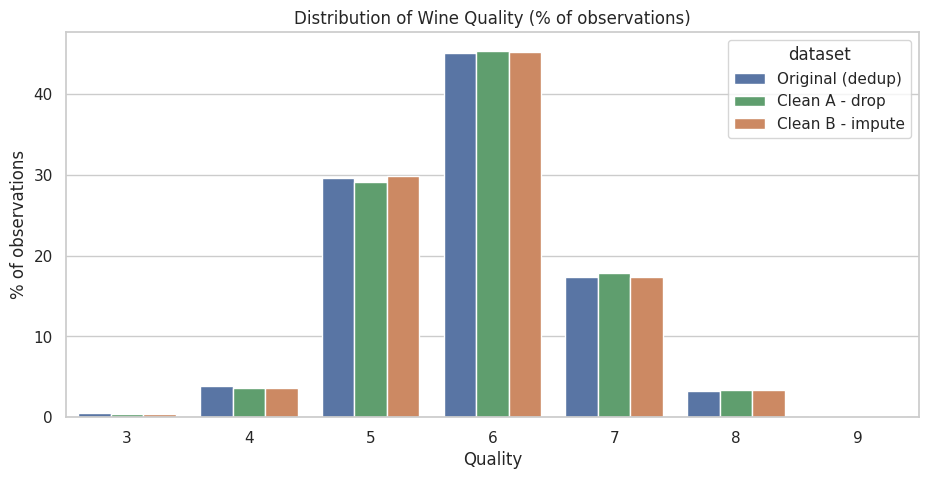

In [76]:
plot_df = quality_pct.reset_index(names="quality").melt(id_vars="quality", var_name="dataset", value_name="percentage")

plt.figure(figsize=(11, 5))
sns.barplot(data=plot_df, x="quality", y="percentage", hue="dataset", palette=PALETTE)
plt.title("Distribution of Wine Quality (% of observations)")
plt.xlabel("Quality")
plt.ylabel("% of observations")
plt.show()

In [77]:
# Chi-square test of homogeneity: are the class proportions the same as the reference?
ref_counts = datasets[REFERENCE][TARGET].value_counts().sort_index()
for name in ["Clean A - drop", "Clean B - impute"]:
    counts = datasets[name][TARGET].value_counts().reindex(ref_counts.index, fill_value=0)
    chi2, p, _, _ = stats.chi2_contingency(np.vstack([ref_counts.values, counts.values]))
    print(f"{name:18s} vs {REFERENCE}: chi2 = {chi2:6.2f}, p-value = {p:.3f}")

Clean A - drop     vs Original (dedup): chi2 =   1.03, p-value = 0.984
Clean B - impute   vs Original (dedup): chi2 =   0.46, p-value = 0.998


A p-value above 0.05 means we find **no evidence** that the class proportions differ. The class imbalance seen in the
original (qualities 5–7 dominate; 3 and 9 are rare) is preserved by both strategies, because we only removed rows at random
positions, never based on the label value.

## 8.3 Univariate analysis

In [78]:
def univariate_summary(d):
    s = d[numeric_features]
    return pd.DataFrame({
        "mean": s.mean(), "median": s.median(), "std": s.std(),
        "min": s.min(), "max": s.max(),
        "skewness": s.skew(), "kurtosis": s.kurt(),
    })

univariate = pd.concat({name: univariate_summary(d) for name, d in datasets.items()}, axis=1)
univariate.xs("mean", axis=1, level=1).round(4)

,Original (dedup),Clean A - drop,Clean B - impute
fixed acidity,6.8393,6.8425,6.8453
volatile acidity,0.2805,0.2799,0.2795
citric acid,0.3343,0.3349,0.3337
residual sugar,5.9148,6.0945,6.1034
chlorides,0.0459,0.0459,0.0457
free sulfur dioxide,34.8892,34.9981,34.9528
total sulfur dioxide,137.1935,137.7927,138.3584
density,0.9938,0.9938,0.9939
pH,3.1955,3.1953,3.1919
sulphates,0.4904,0.4918,0.4898


In [79]:
# Relative difference (%) of each statistic vs the reference
rel_diff = {}
ref_stats = univariate_summary(datasets[REFERENCE])
for name in ["Clean A - drop", "Clean B - impute"]:
    s = univariate_summary(datasets[name])
    rel_diff[name] = ((s - ref_stats) / ref_stats.abs() * 100)[["mean", "median", "std", "skewness"]]

pd.concat(rel_diff, axis=1).round(1)

Clean A - drop                      Clean B - impute                     
                               mean median  std skewness             mean median  std skewness
fixed acidity                   0.0    0.0 -0.4      3.1              0.1    0.0 -2.1     -1.6
volatile acidity               -0.2    0.0 -2.8     -9.3             -0.4    0.0 -3.0     -6.4
citric acid                     0.2    0.0  1.0     11.2             -0.2    0.0 -1.0      1.8
residual sugar                  3.0    4.3  2.1     -2.9              3.2    8.5  3.6     29.6
chlorides                       0.0    2.4 -0.8     -1.6             -0.3    2.4 -3.2      1.5
free sulfur dioxide             0.3    0.0  0.3     17.2              0.2    3.0 -1.5      5.0
total sulfur dioxide            0.4    0.0  2.6     56.1              0.8    0.8  0.7     43.2
density                         0.0    0.0 -2.2    -72.7              0.0    0.0 -0.3     -3.8
pH                             -0.0    0.0 -0.5      2.8             -0.1    0.0 -1.9      3.9
sulphates                       0.3    0.0  1.4      6.2             -0.1   -2.1 -1.1      6.3
alcohol                        -0.1    0.0  0.9     -0.8             -0.3    0.0 -0.6      6.2

**How to read it.** Values are percentage differences against *Original (dedup)*. Means and medians of both cleaned sets
stay within a few percent. The column to watch is **`std`**: imputation (B) tends to *shrink* it, because every imputed
value sits exactly at the center of the distribution. The skewness is the most sensitive
statistic, because it depends heavily on a few extreme (but valid) values. For example, the skewness of `density` changes
a lot in Strategy A simply because the single densest wine (1.039, a very sweet sample) happened to be in a dropped row, while the bulk
of the distribution is unchanged.

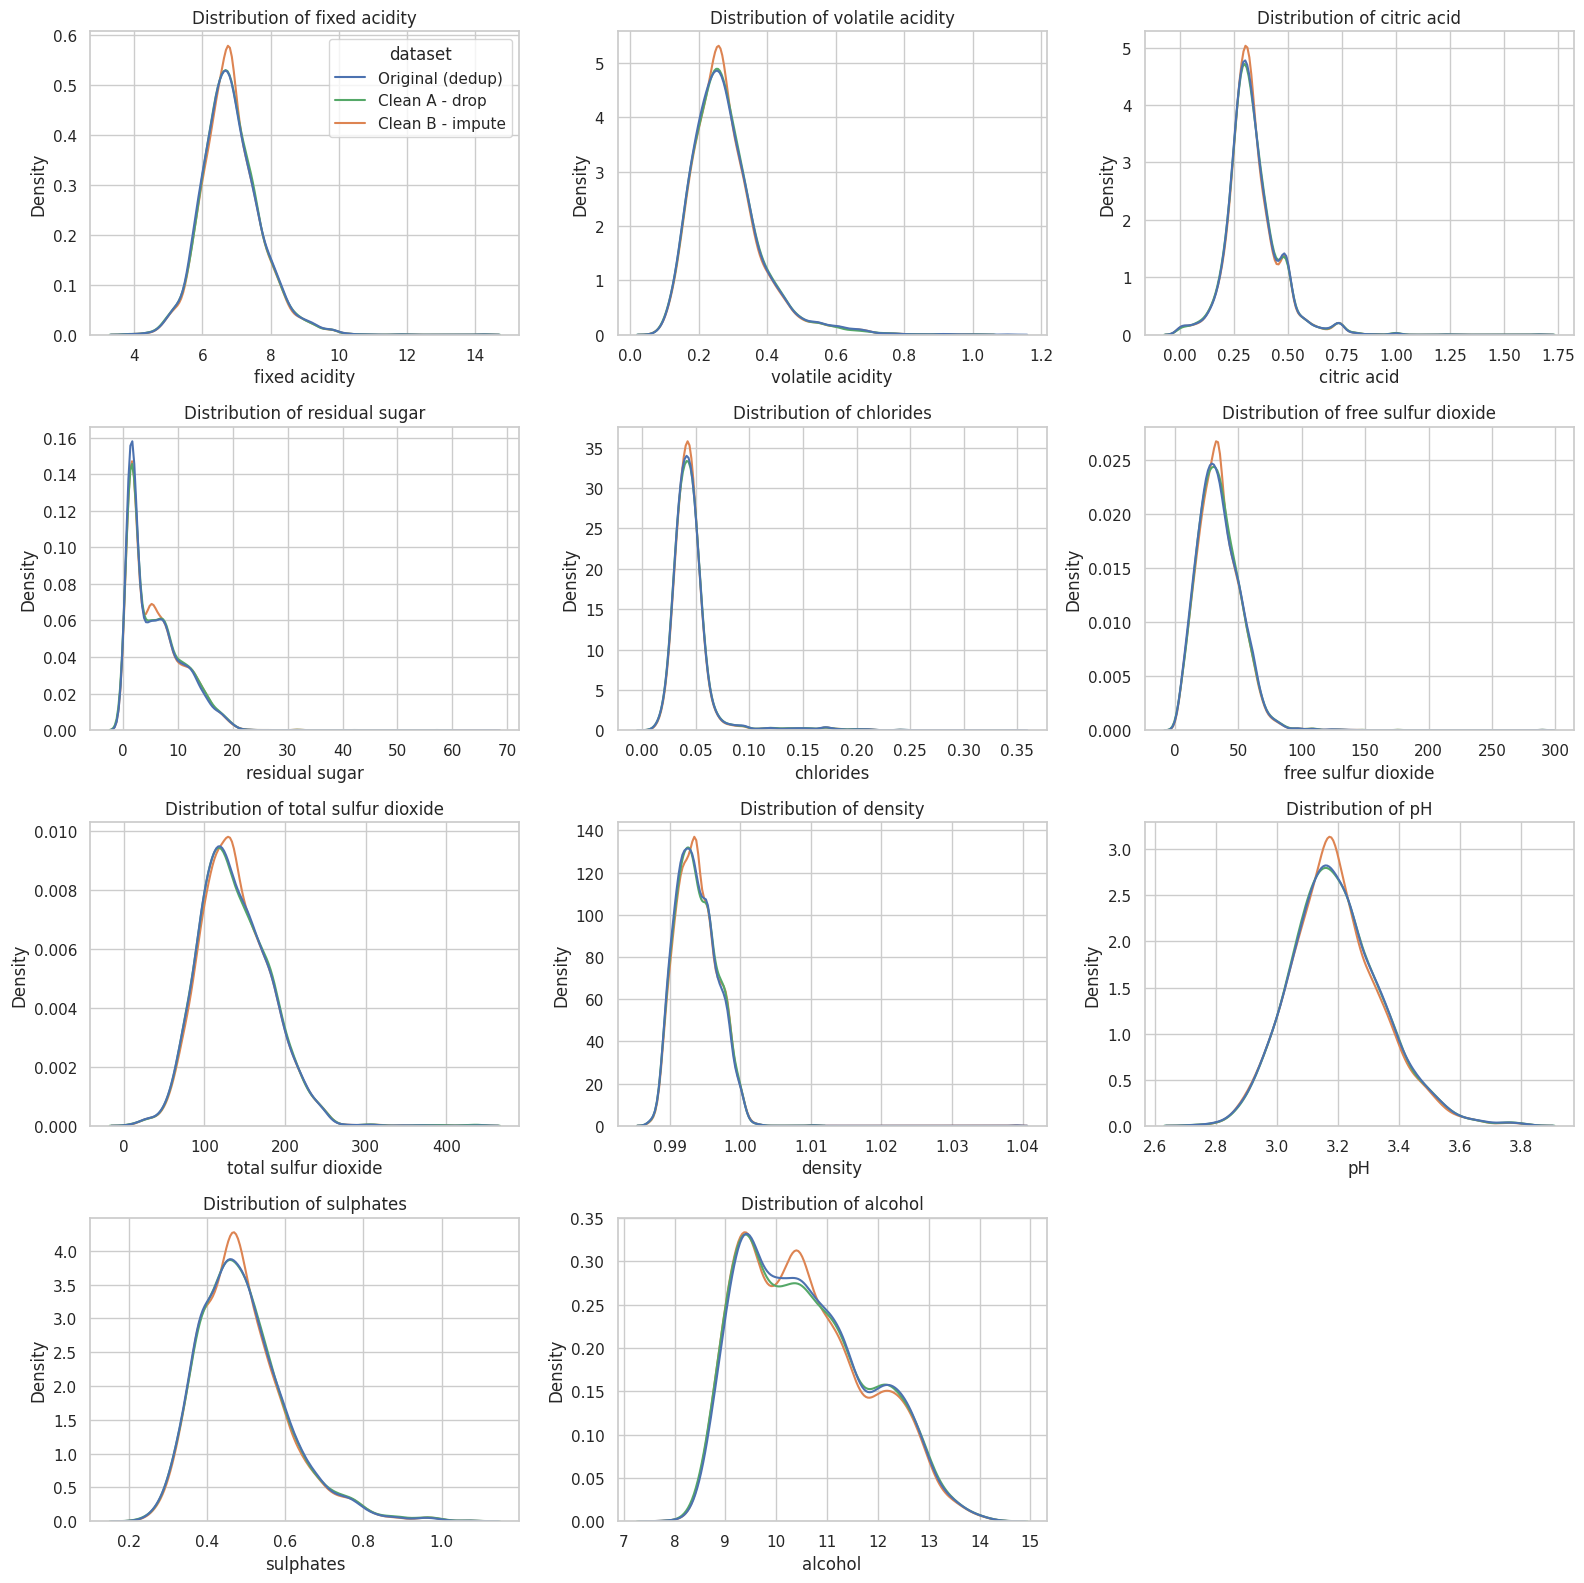

In [80]:
# Distribution overlay: all datasets on the same axes, normalized to density
long_df = long_format(numeric_features)
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
for ax, column in zip(axes.flat, numeric_features):
    sns.kdeplot(data=long_df, x=column, hue="dataset", palette=PALETTE,
                common_norm=False, ax=ax, linewidth=1.5, legend=(column == numeric_features[0]))
    ax.set_title(f"Distribution of {column}")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

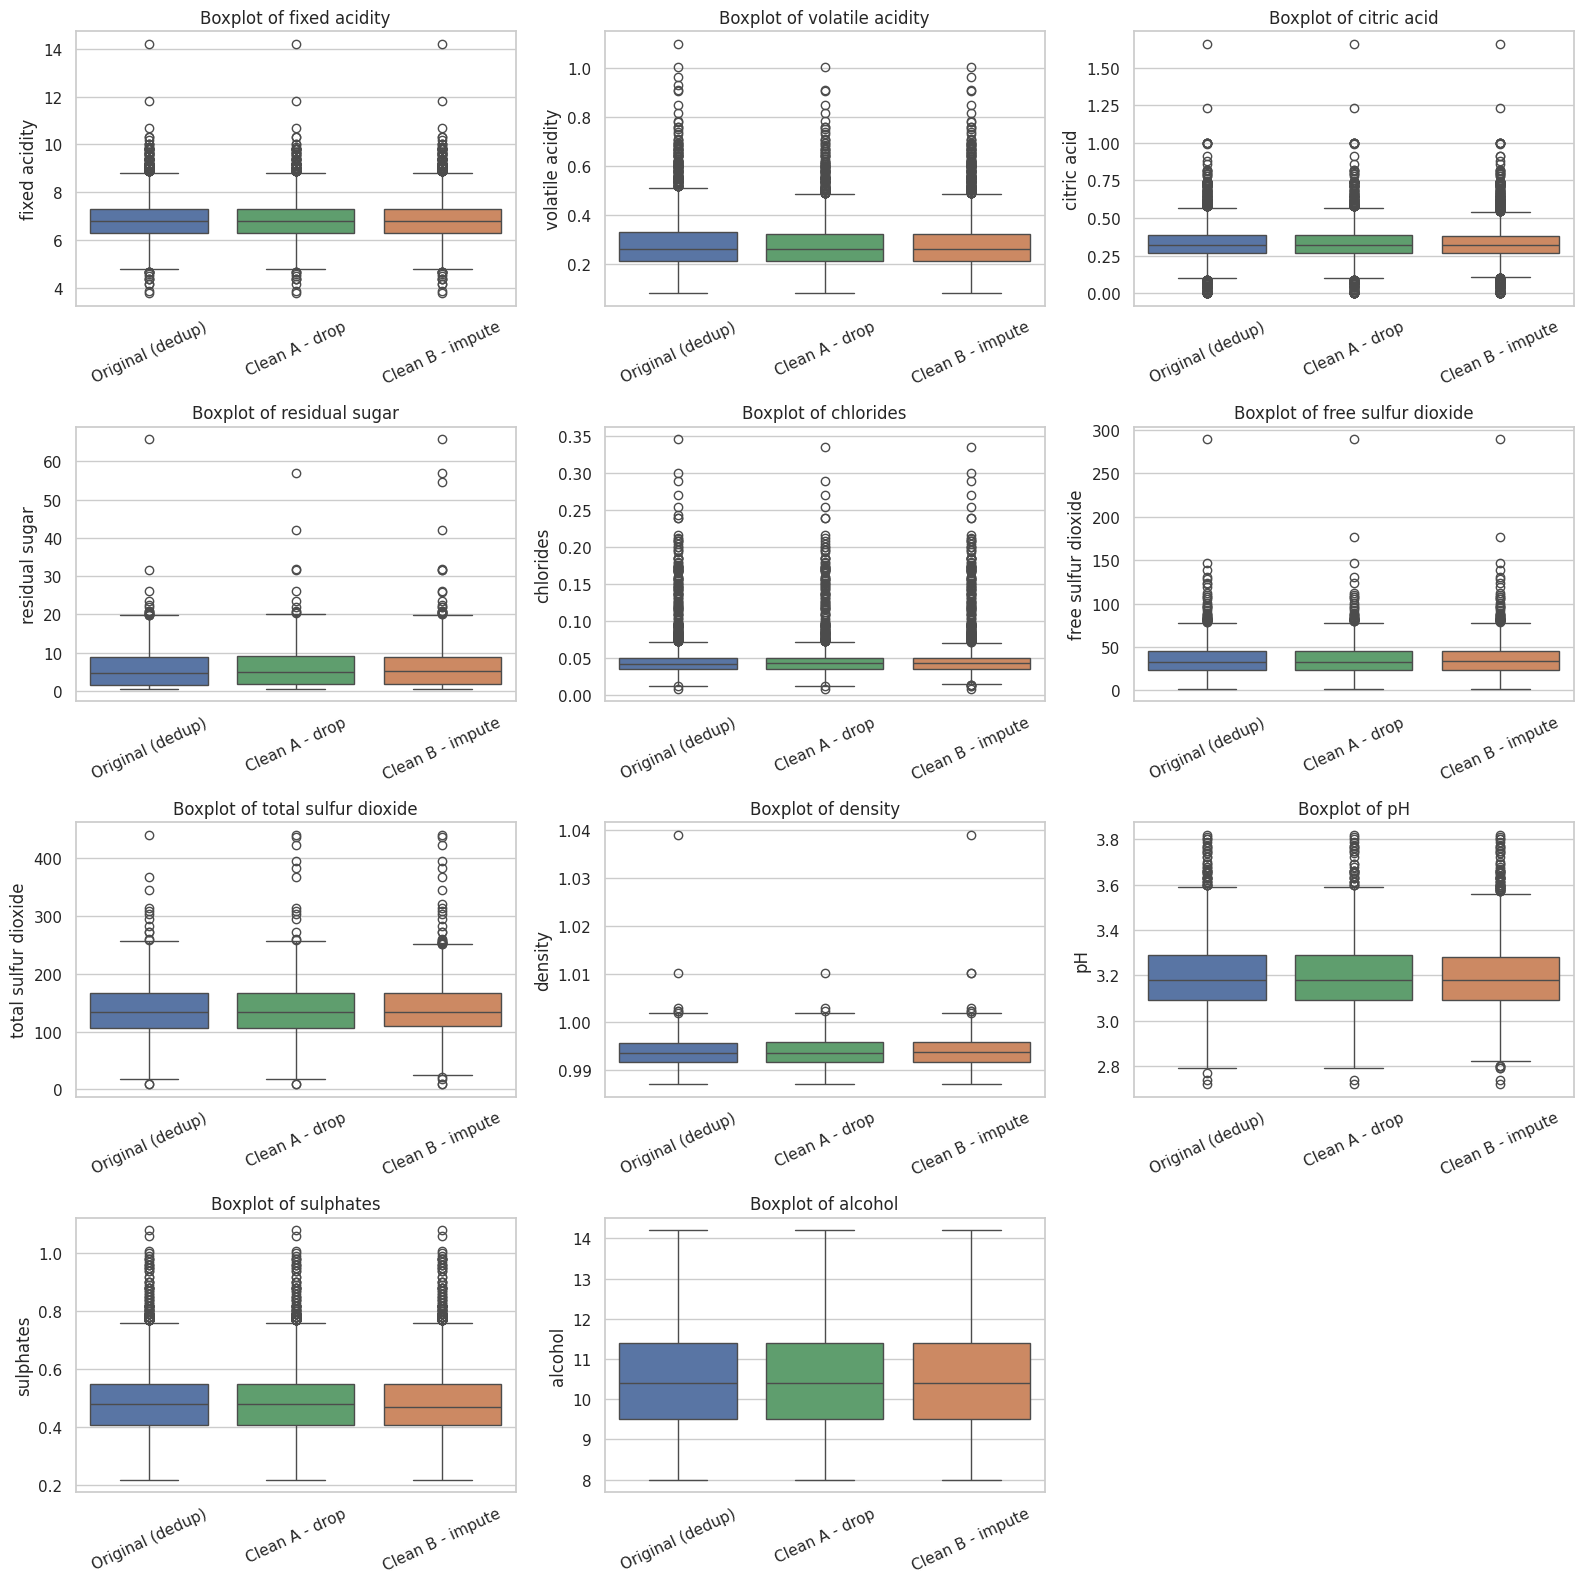

In [81]:
# Boxplots side by side: spread and potential extreme values per dataset
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
for ax, column in zip(axes.flat, numeric_features):
    sns.boxplot(data=long_df, x="dataset", y=column, hue="dataset", palette=PALETTE, ax=ax, legend=False)
    ax.set_title(f"Boxplot of {column}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

The curves of the cleaned datasets lie on top of the originals. For Strategy B, look for a slightly taller, sharper peak
at the median in some variables (clearly visible in `alcohol`, `pH` and `sulphates`): that is the visual signature of
median imputation, since about 1–2% of each column was set to the same value.

## 8.4 Potential outliers using the IQR rule

In [82]:
def iqr_outlier_pct(d):
    out = {}
    for column in numeric_features:
        q1, q3 = d[column].quantile([0.25, 0.75])
        iqr = q3 - q1
        out[column] = 100 * ((d[column] < q1 - 1.5 * iqr) | (d[column] > q3 + 1.5 * iqr)).mean()
    return pd.Series(out)

pd.DataFrame({name: iqr_outlier_pct(d) for name, d in datasets.items()}).round(2)

,Original (dedup),Clean A - drop,Clean B - impute
fixed acidity,2.68,2.53,2.54
volatile acidity,3.36,3.93,3.98
citric acid,5.63,5.53,6.74
residual sugar,0.40,0.32,0.49
chlorides,4.49,4.51,4.31
free sulfur dioxide,1.11,1.12,1.08
total sulfur dioxide,0.35,0.48,0.68
density,0.15,0.10,0.16
pH,1.16,1.09,1.53
sulphates,2.42,2.72,2.52


The percentage of *potential* outliers per feature is similar across datasets. This confirms that cleaning removed the
injected **errors** but not the natural tails: genuine unusual wines are still there, as they should be.

## 8.5 Bivariate analysis: predictors vs. wine quality

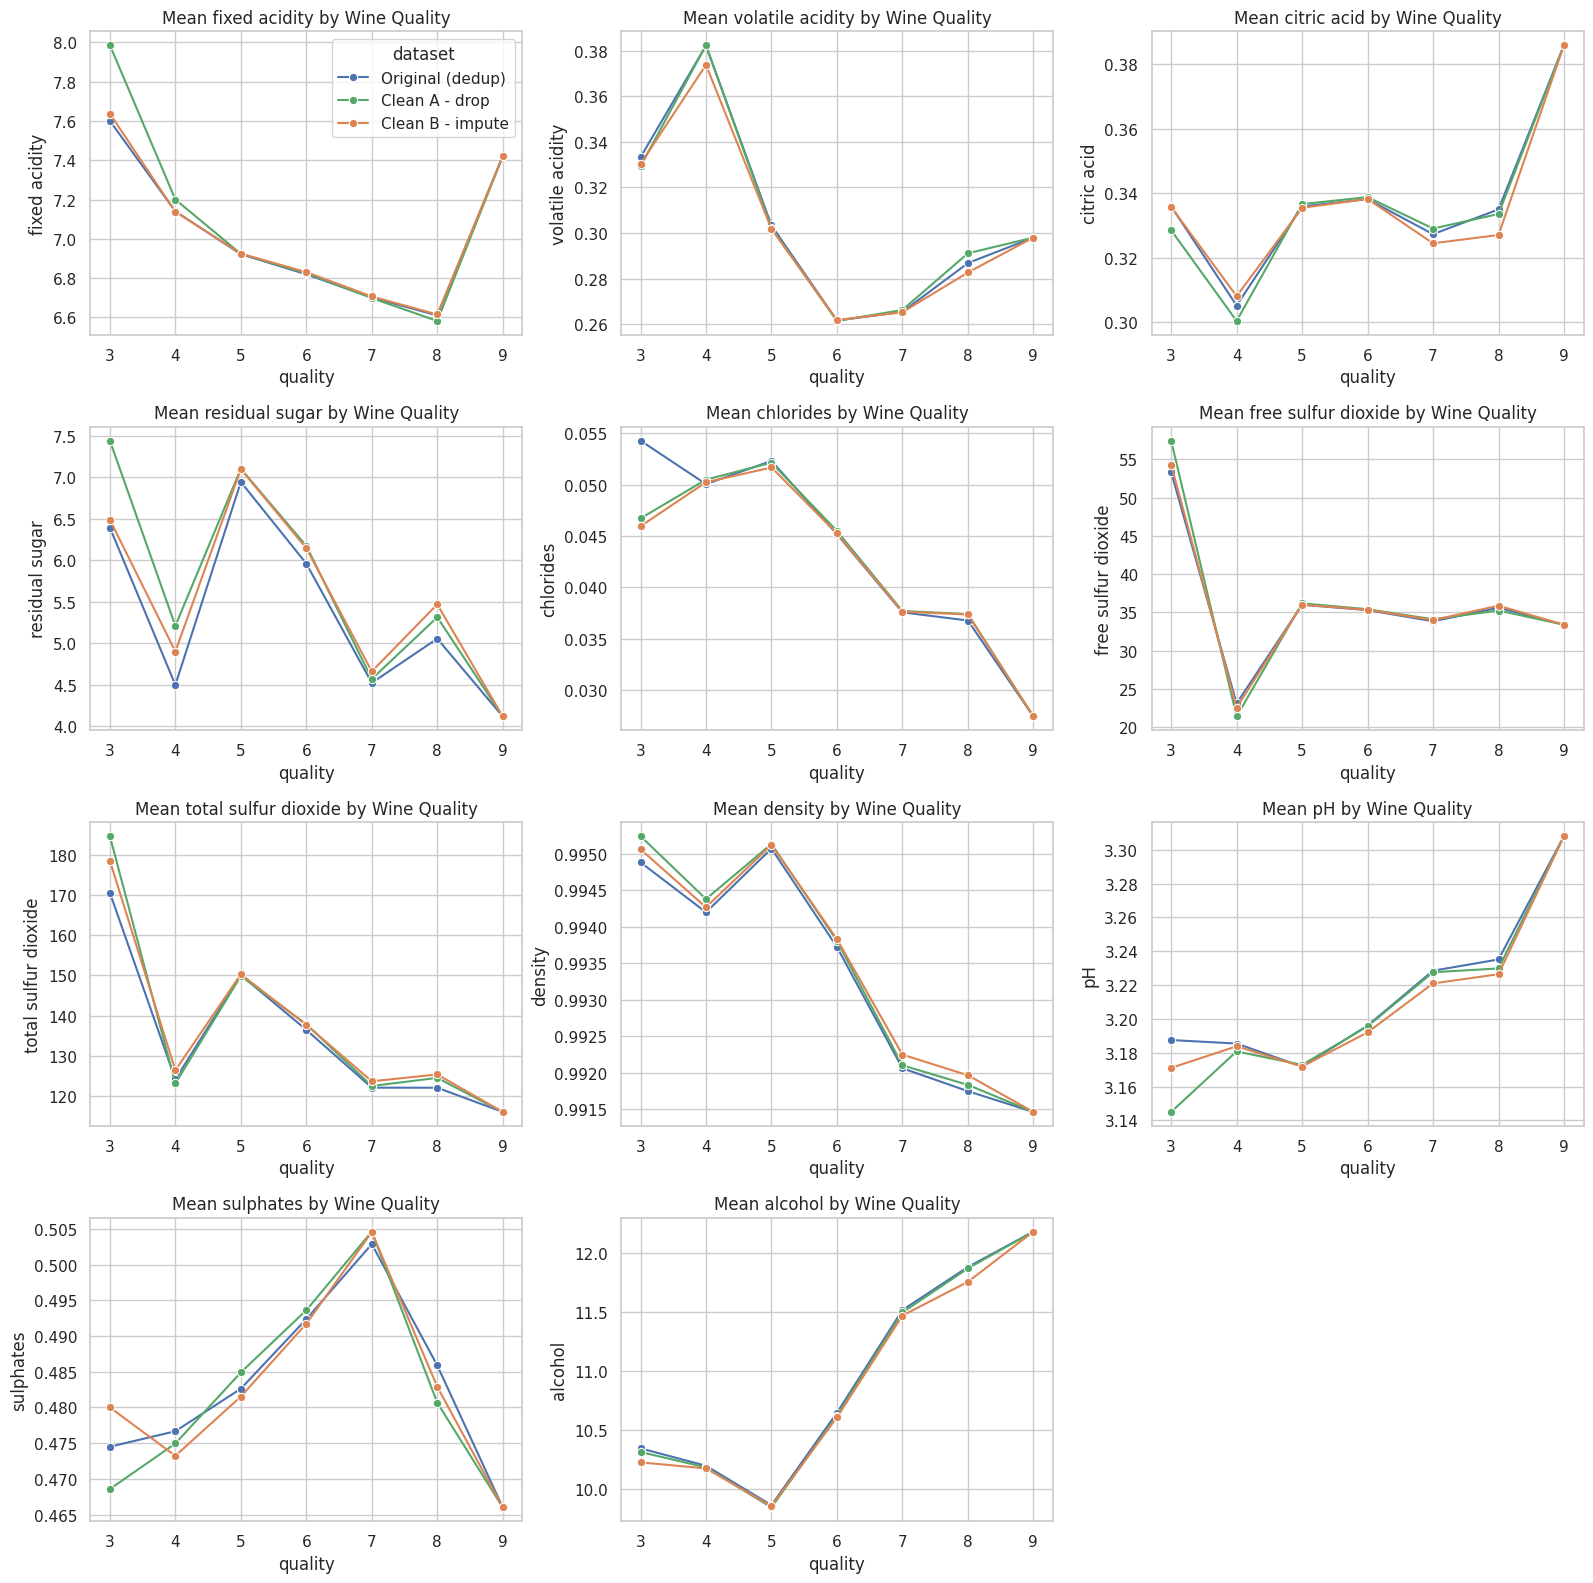

In [83]:
# Mean of each feature by quality level, one line per dataset
means_by_quality = pd.concat(
    [d.groupby(TARGET)[numeric_features].mean().assign(dataset=name).reset_index()
     for name, d in datasets.items()],
    ignore_index=True,
)
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
for ax, column in zip(axes.flat, numeric_features):
    sns.lineplot(data=means_by_quality, x=TARGET, y=column, hue="dataset", palette=PALETTE,
                 marker="o", ax=ax, legend=(column == numeric_features[0]))
    ax.set_title(f"Mean {column} by Wine Quality")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

The trends (e.g. alcohol rising with quality, density falling) are preserved. Small deviations appear at quality 3 and 9,
which have very few wines, so every removed row weighs more there.

## 8.6 Correlation analysis (Pearson and Spearman)

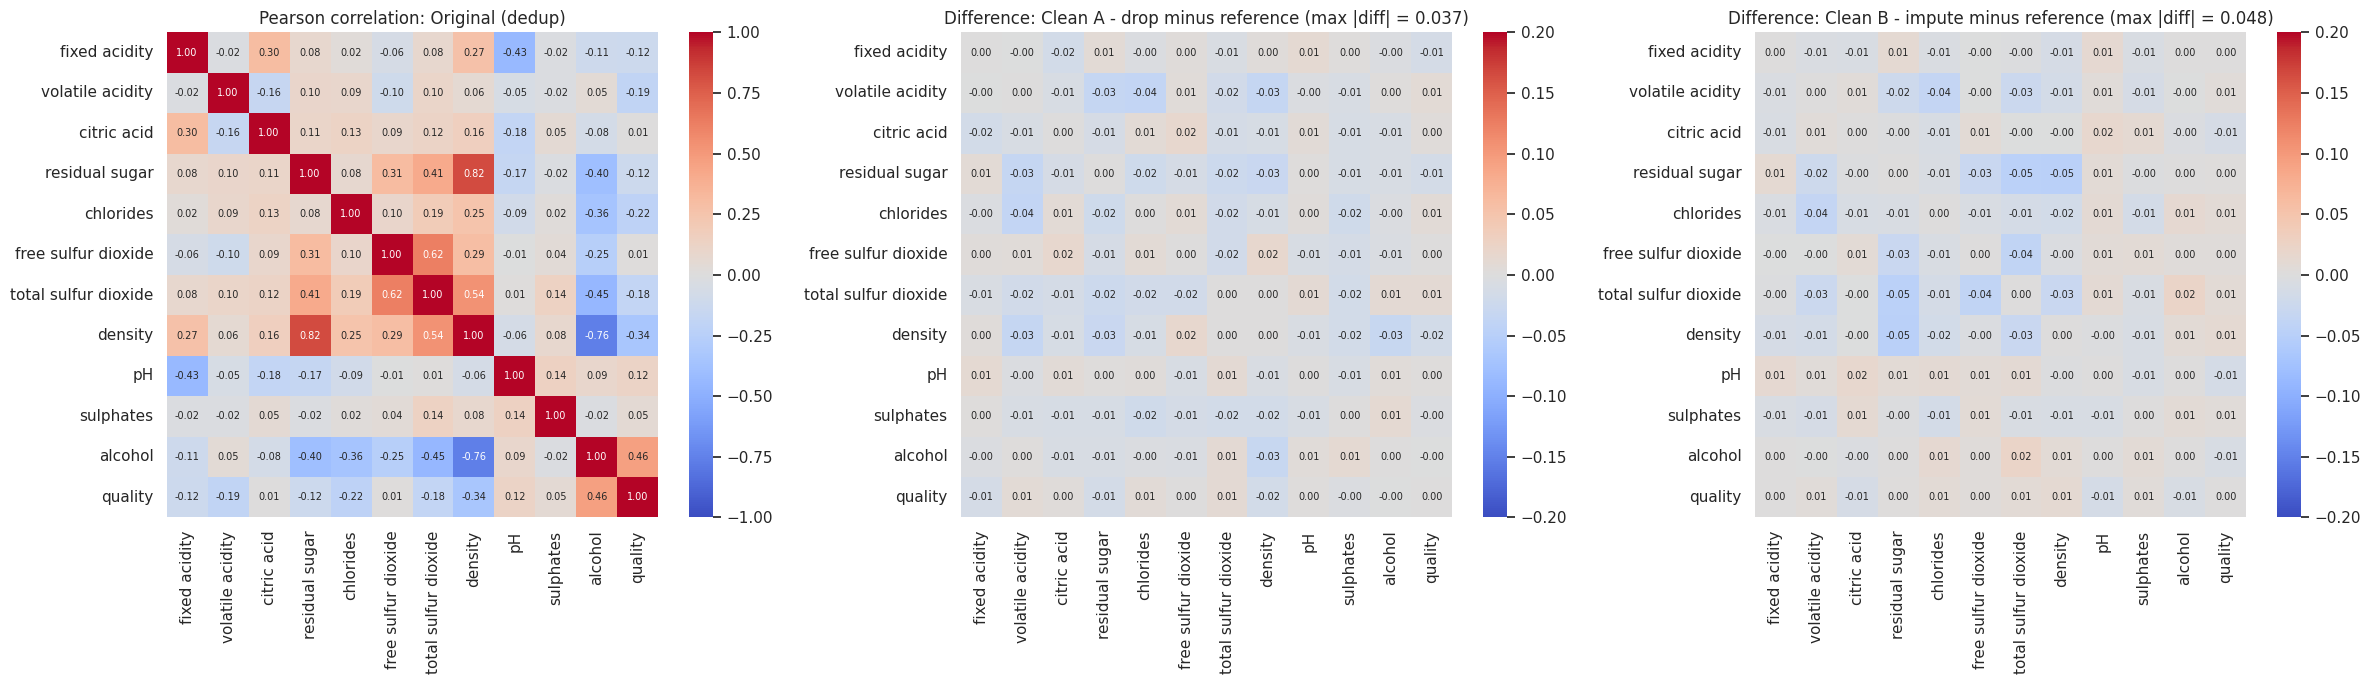

In [84]:
corr_cols = numeric_features + [TARGET]

def corr_diff_heatmaps(method):
    ref = datasets[REFERENCE][corr_cols].corr(method=method)
    fig, axes = plt.subplots(1, 3, figsize=(24, 7))
    sns.heatmap(ref, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[0], annot=True, fmt=".2f", annot_kws={"size": 7})
    axes[0].set_title(f"{method.title()} correlation: {REFERENCE}")
    for ax, name in zip(axes[1:], ["Clean A - drop", "Clean B - impute"]):
        diff = datasets[name][corr_cols].corr(method=method) - ref
        sns.heatmap(diff, cmap="coolwarm", center=0, vmin=-0.2, vmax=0.2, ax=ax, annot=True, fmt=".2f", annot_kws={"size": 7})
        ax.set_title(f"Difference: {name} minus reference (max |diff| = {diff.abs().max().max():.3f})")
    plt.tight_layout()
    plt.show()

corr_diff_heatmaps("pearson")

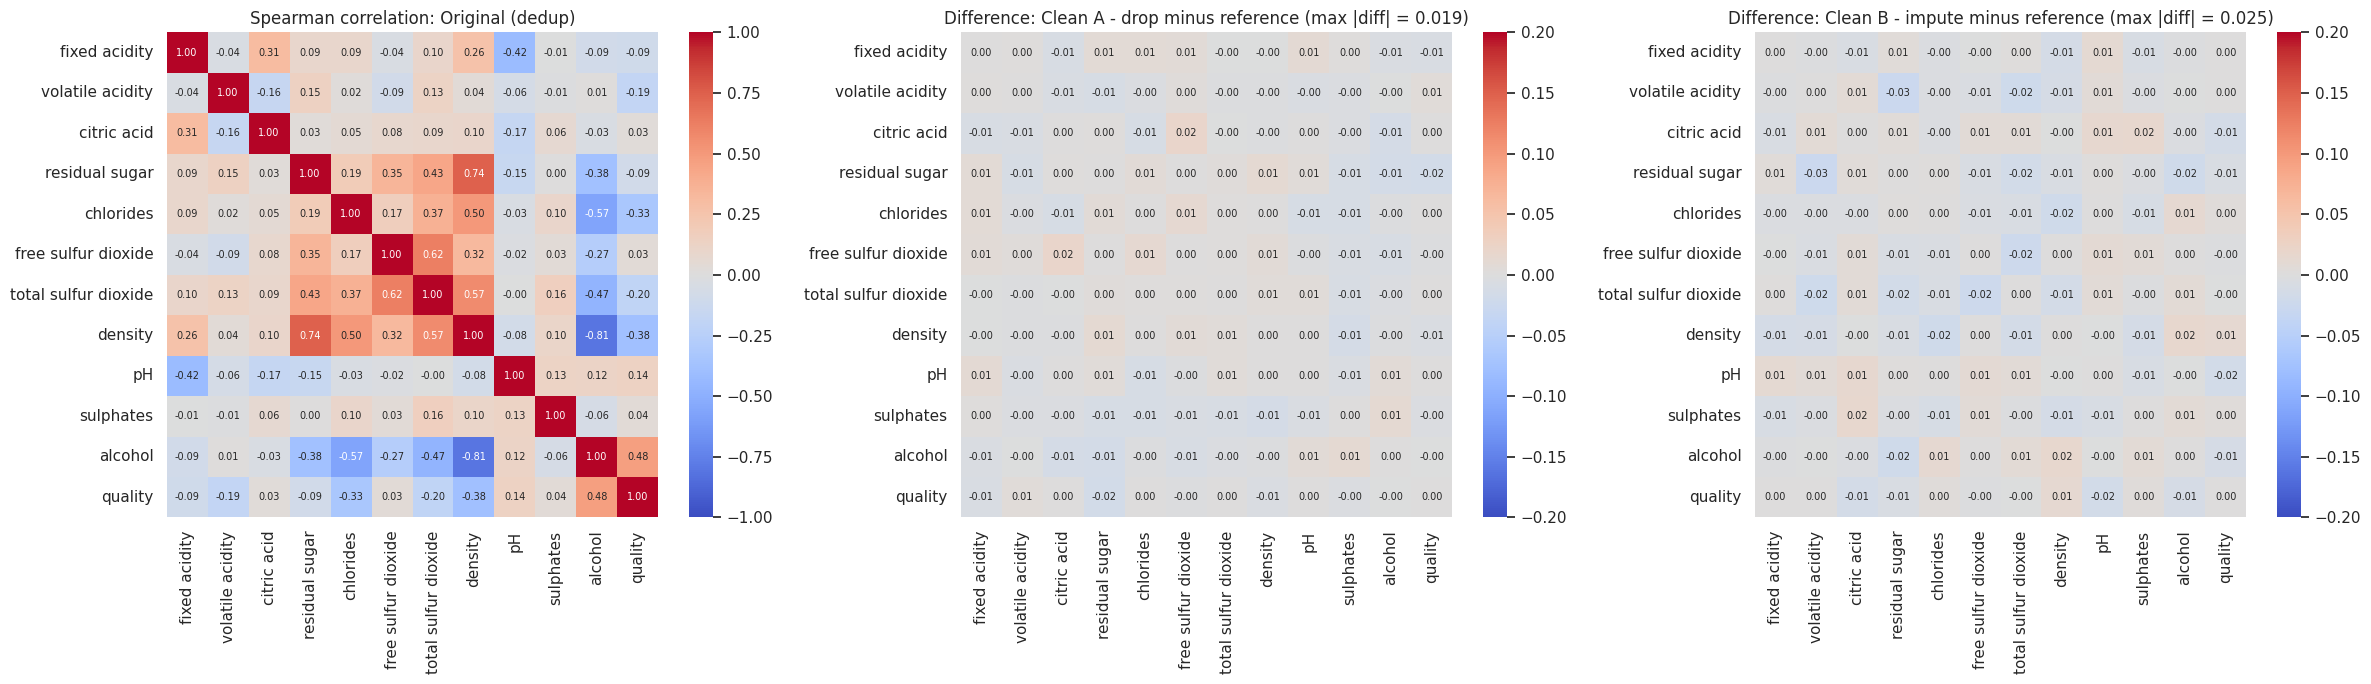

In [85]:
corr_diff_heatmaps("spearman")

The difference heatmaps use a narrow color scale (±0.2) so that small changes become visible. Near-white cells mean the
relationship between two variables is unchanged by cleaning.

In [86]:
# Correlation with quality: the numbers that most often drive feature selection
quality_corr = pd.DataFrame({
    name: d[corr_cols].corr(method="pearson")[TARGET].drop(TARGET) for name, d in datasets.items()
})
quality_corr.sort_values(REFERENCE, key=lambda s: s.abs(), ascending=False).round(3)

,Original (dedup),Clean A - drop,Clean B - impute
alcohol,0.463,0.463,0.454
density,-0.338,-0.354,-0.325
chlorides,-0.218,-0.211,-0.209
volatile acidity,-0.191,-0.181,-0.185
total sulfur dioxide,-0.183,-0.174,-0.175
fixed acidity,-0.125,-0.137,-0.124
pH,0.124,0.126,0.111
residual sugar,-0.117,-0.132,-0.115
sulphates,0.053,0.049,0.059
free sulfur dioxide,0.011,0.012,0.015


In [87]:
# Ranking of features by |correlation with quality|: does cleaning change which features look important?
top_k = 5
rankings = {name: quality_corr[name].abs().sort_values(ascending=False).head(top_k).index.tolist()
            for name in datasets}
pd.DataFrame(rankings, index=[f"#{i + 1}" for i in range(top_k)])

,Original (dedup),Clean A - drop,Clean B - impute
#1,alcohol,alcohol,alcohol
#2,density,density,density
#3,chlorides,chlorides,chlorides
#4,volatile acidity,volatile acidity,volatile acidity
#5,total sulfur dioxide,total sulfur dioxide,total sulfur dioxide


## 8.7 Standardized multivariate profile by quality

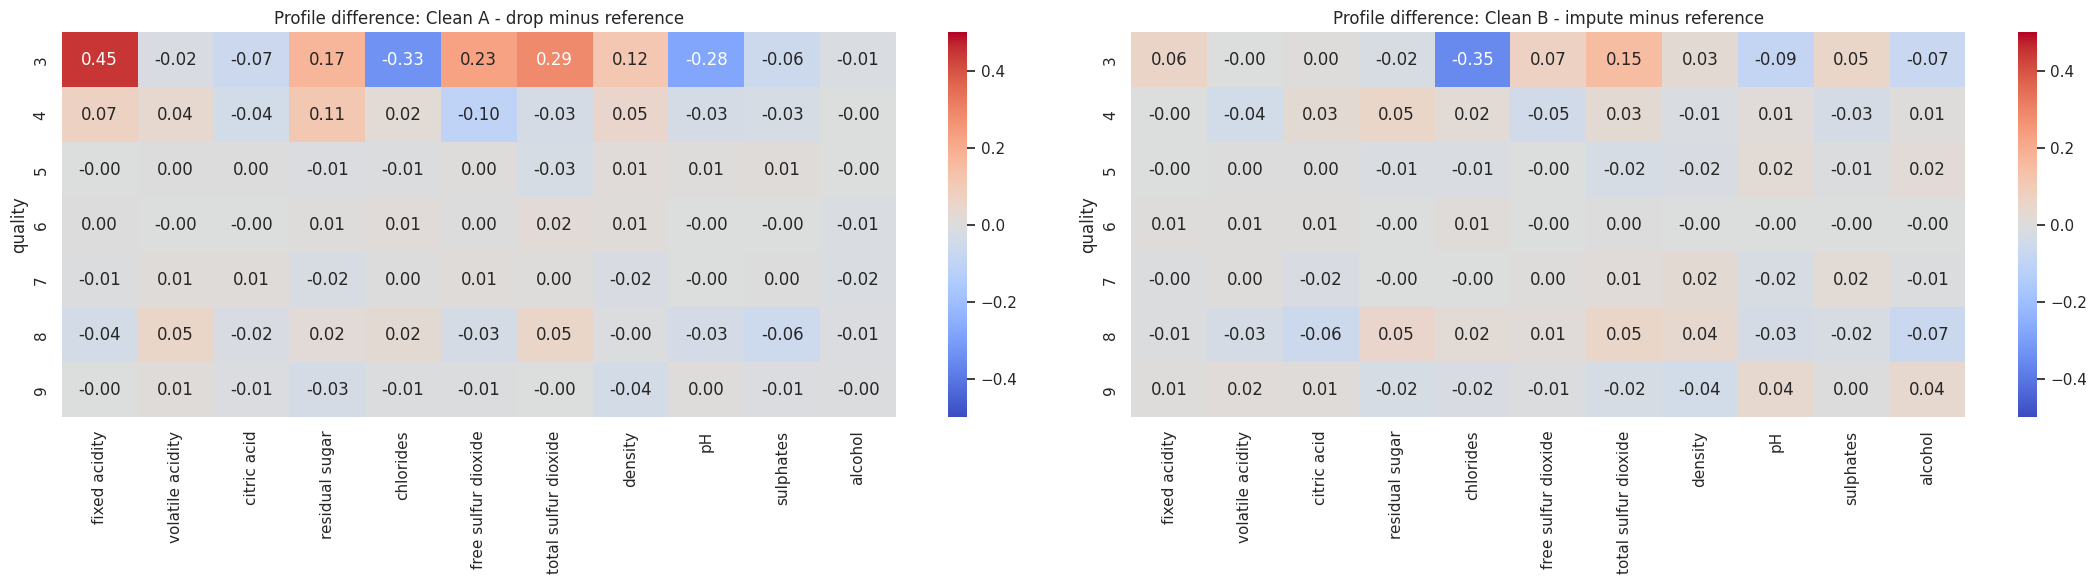

In [88]:
def standardized_profile(d):
    means = d.groupby(TARGET)[numeric_features].mean()
    return (means - d[numeric_features].mean()) / d[numeric_features].std()

ref_profile = standardized_profile(datasets[REFERENCE])
fig, axes = plt.subplots(1, 2, figsize=(22, 6))
for ax, name in zip(axes, ["Clean A - drop", "Clean B - impute"]):
    diff = standardized_profile(datasets[name]) - ref_profile
    sns.heatmap(diff, cmap="coolwarm", center=0, vmin=-0.5, vmax=0.5, annot=True, fmt=".2f", ax=ax)
    ax.set_title(f"Profile difference: {name} minus reference")
plt.tight_layout()
plt.show()

## 8.8 Formal distribution tests

Plots are persuasive but subjective. Three numeric checks make "the distributions correspond" measurable:

| Metric | What it measures | Rule of thumb for "equivalent" |
|---|---|---|
| **Two-sample Kolmogorov–Smirnov (KS)** | Largest gap between the two cumulative distributions | p-value > 0.05 (no evidence of a difference) |
| **Standardized mean difference (SMD)** | Shift of the mean, in reference standard deviations | \|SMD\| < 0.1 is negligible |
| **Variance ratio** | Spread of cleaned / spread of reference | between 0.9 and 1.1 |

> KS on a discrete variable such as `quality` is conservative because of ties; the chi-square test in 8.2 is the proper
> test for the target.

In [89]:
def distribution_tests(name, ref_name=REFERENCE):
    ref, d = datasets[ref_name], datasets[name]
    rows = []
    for column in numeric_features:
        ks = stats.ks_2samp(ref[column], d[column])
        rows.append({
            "feature": column,
            "ks_stat": ks.statistic,
            "ks_pvalue": ks.pvalue,
            "smd": (d[column].mean() - ref[column].mean()) / ref[column].std(),
            "variance_ratio": d[column].var() / ref[column].var(),
        })
    out = pd.DataFrame(rows).set_index("feature")
    out["equivalent"] = (out["ks_pvalue"] > 0.05) & (out["smd"].abs() < 0.1) & out["variance_ratio"].between(0.9, 1.1)
    return out

tests_a = distribution_tests("Clean A - drop")
tests_a.round(4)

,ks_stat,ks_pvalue,smd,variance_ratio,equivalent
feature,,,,,
fixed acidity,0.0066,1.0000,0.0037,0.9921,True
volatile acidity,0.0061,1.0000,-0.0063,0.9441,True
citric acid,0.0056,1.0000,0.0050,1.0194,True
residual sugar,0.0165,0.7170,0.0370,1.0426,True
chlorides,0.0074,1.0000,0.0005,0.9838,True
free sulfur dioxide,0.0087,0.9992,0.0063,1.0065,True
total sulfur dioxide,0.0073,1.0000,0.0139,1.0527,True
density,0.0129,0.9285,0.0190,0.9568,True
pH,0.0030,1.0000,-0.0013,0.9909,True


In [90]:
tests_b = distribution_tests("Clean B - impute")
tests_b.round(4)

,ks_stat,ks_pvalue,smd,variance_ratio,equivalent
feature,,,,,
fixed acidity,0.0199,0.3851,0.0069,0.9583,True
volatile acidity,0.0139,0.8141,-0.0100,0.9407,True
citric acid,0.0169,0.5956,-0.0055,0.9808,True
residual sugar,0.0302,0.0467,0.0388,1.0728,False
chlorides,0.0188,0.4594,-0.0068,0.9373,True
free sulfur dioxide,0.0193,0.4222,0.0037,0.9698,True
total sulfur dioxide,0.0236,0.1991,0.0270,1.0131,True
density,0.0305,0.0435,0.0376,0.9937,False
pH,0.0226,0.2424,-0.0236,0.9617,True


In [91]:
# Scorecard: both cleaned datasets against the deduplicated original
def corr_gap(name, ref_name=REFERENCE):
    return (datasets[name][corr_cols].corr() - datasets[ref_name][corr_cols].corr()).abs().max().max()

scorecard = []
for name in ["Clean A - drop", "Clean B - impute"]:
    t = distribution_tests(name)
    scorecard.append({
        "cleaned": name, "reference": REFERENCE, "rows": len(datasets[name]),
        "features_equivalent": f"{int(t['equivalent'].sum())}/{len(t)}",
        "min_ks_pvalue": t["ks_pvalue"].min(),
        "max_abs_smd": t["smd"].abs().max(),
        "variance_ratio_range": f"{t['variance_ratio'].min():.3f} - {t['variance_ratio'].max():.3f}",
        "max_abs_corr_diff": corr_gap(name),
    })
pd.DataFrame(scorecard).set_index("cleaned").round(4)

,reference,rows,features_equivalent,min_ks_pvalue,max_abs_smd,variance_ratio_range,max_abs_corr_diff
cleaned,,,,,,,
Clean A - drop,Original (dedup),3126,11/11,0.7170,0.0370,0.944 - 1.053,0.0374
Clean B - impute,Original (dedup),4245,9/11,0.0435,0.0388,0.937 - 1.073,0.0475


# 9. Conclusions

**What the tests found and how each was fixed**

| Problem found by | Cleanup action |
|---|---|
| T1 schema | Dropped the noise column `mixed_type_col` |
| T2/T3 types & whitespace | Stripped spaces, cast to numeric explicitly |
| T4/T5 placeholders & missing | Mapped `?`, `n/a`, `error`, `invalid`, `null`, `NaN` to missing |
| T6 domain ranges | Impossible values (10–1000× normal) set to missing |
| T7 consistency | Free SO₂ > total SO₂ → both set to missing |
| T8 target | Rows with invalid `quality` dropped; target cast to integer |
| T9 duplicates | Exact duplicates dropped after normalization |

**Which strategy reproduces the original EDA better?** The scorecard in 8.8 answers it (values from this run):

| vs. Original (dedup), 3,961 rows | Features equivalent | Min KS p-value | Max \|Δcorr\| |
|---|---|---|---|
| **A: drop rows** (3,126 rows) | **11/11** | ≈ 0.72 | ≈ 0.04 |
| **B: impute** (4,245 rows) | 9/11 (`residual sugar`, `density` fail KS narrowly) | ≈ 0.04 | ≈ 0.05 |

- **Strategy A (drop rows)** keeps only genuine measurements, so its distributions, spread and correlations match the
  deduplicated original closely. It costs about a quarter of the rows. That is affordable here because the corruption was random
  (missing completely at random, MCAR) and thousands of rows remain.
- **Strategy B (median imputation)** keeps more rows, but about 1–2% of every column is set to one identical value. The effect
  is visible as sharp peaks in the KDE plots (8.3), and the KS test picks it up for two features. The target distribution, the
  feature ranking by correlation with quality, and the quality profiles are still preserved, so B remains usable when rows are
  scarce, as long as its bias is acknowledged.
- With both strategies, the class balance of `quality` is unchanged (chi-square p > 0.98) and the top-5 features most
  correlated with quality are identical to the original.
- Deduplication itself changes the statistics of the original (e.g. the mean `residual sugar` drops by about 7.5%). That is why
  the baseline was deduplicated with the same rule. Dropping duplicates is a **modelling decision**, not a cleaning error: the
  original contains legitimate repeated measurements, and whichever rule is chosen must be applied consistently to training,
  validation and production data.

**MLOps take-aways**

1. **Test first, then clean.** Every action above is justified by a measured test result.
2. **Write the data contract down** and validate the output against it automatically (Section 6).
3. **Errors ≠ outliers.** Domain rules remove impossible values; statistical rules (IQR) are diagnostics.
4. **Never impute the target**, and fit imputers on the training split only.
5. **Log** every cleaning run (`cleaning_log`) so results are traceable. Here the cleaned CSVs are overwritten on each run;
   in production a data-versioning tool (e.g. DVC) would keep their history.

The baseline `original_no_duplicates.csv` and its full single-dataset EDA come from notebook
`1.3_WineData_EDA_Example.ipynb`.